In [1]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
import pprint
import pyspark
import pyspark.sql.functions as F
import seaborn as sns

from pyspark.sql.functions import col
from pyspark.sql.types import StringType, IntegerType, FloatType, DateType

import utils.data_processing_bronze_table
import utils.data_processing_attribute_silver_table
import utils.data_processing_financials_silver_table
import utils.data_processing_clickstream_silver_table
import utils.data_processing_lms_silver_table
import utils.data_processing_lms_gold_table

pd.set_option("display.max_columns", None)

In [2]:
# Initialize SparkSession
spark = (
    pyspark.sql.SparkSession.builder
.appName("dev")
.master("local[*]")
.getOrCreate()
)

# Set log level to ERROR to hide warnings
spark.sparkContext.setLogLevel("ERROR")

# star is to use all available resources on the local machine. You can also specify a number, e.g., "local[4]" to use 4 cores.

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/10 06:46:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/10 06:46:55 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


In [12]:
gold_loan_filename = "datamart/gold/label_store/gold_label_store_main_.parquet"
labels_sf = spark.read.option("header", "true").parquet(gold_loan_filename)
labels_df = labels_sf.toPandas()
labels_df.head()


,loan_id,Customer_ID,label,label_def,snapshot_date
0,CUS_0x5002_2023_04_01,CUS_0x5002,1,30dpd_6mob,2023-10-01
1,CUS_0x500d_2024_12_01,CUS_0x500d,1,30dpd_6mob,2025-06-01
2,CUS_0x5012_2023_11_01,CUS_0x5012,1,30dpd_6mob,2024-05-01
3,CUS_0x501c_2024_03_01,CUS_0x501c,1,30dpd_6mob,2024-09-01
4,CUS_0x501d_2024_02_01,CUS_0x501d,0,30dpd_6mob,2024-08-01


In [13]:
sorted(labels_df['snapshot_date'].unique())

[datetime.date(2023, 7, 1),
 datetime.date(2023, 8, 1),
 datetime.date(2023, 9, 1),
 datetime.date(2023, 10, 1),
 datetime.date(2023, 11, 1),
 datetime.date(2023, 12, 1),
 datetime.date(2024, 1, 1),
 datetime.date(2024, 2, 1),
 datetime.date(2024, 3, 1),
 datetime.date(2024, 4, 1),
 datetime.date(2024, 5, 1),
 datetime.date(2024, 6, 1),
 datetime.date(2024, 7, 1),
 datetime.date(2024, 8, 1),
 datetime.date(2024, 9, 1),
 datetime.date(2024, 10, 1),
 datetime.date(2024, 11, 1),
 datetime.date(2024, 12, 1),
 datetime.date(2025, 1, 1),
 datetime.date(2025, 2, 1),
 datetime.date(2025, 3, 1),
 datetime.date(2025, 4, 1),
 datetime.date(2025, 5, 1),
 datetime.date(2025, 6, 1),
 datetime.date(2025, 7, 1)]

In [4]:
fs_sdf = spark.read.option("header", "true").parquet('datamart/gold/feature_store/gold_feature_store_main_.parquet')
fs_pdf = fs_sdf.toPandas()
fs_pdf.head()

,Occupation,Age_Bin,Customer_ID,loan_id,labels_snapshot_date,Age,attributes_snapshot_date,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance,financials_snapshot_date,Num_of_Loan_Cleaned,Loan_Home_Equity_Loan,Loan_Payday_Loan,Loan_Personal_Loan,Loan_Debt_Consolidation_Loan,Loan_Mortgage_Loan,Loan_Student_Loan,Loan_Credit_Builder_Loan,Loan_Auto_Loan,Loan_Not_Specified,Credit_Mix_Not_Defined,Credit_Mix_Good,Credit_Mix_Bad,Credit_Mix_Standard,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Credit_History_Age_Years,Payment_Behaviour_Imputed,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,clicks_snapshot_date,Age_imputed,Bank_Accounts_imputed,Credit_Cards_imputed,Bank_Accounts_Imputed_Bin,Credit_Cards_Imputed_Bin,Debt_per_Credit_Account,Delayed_Payments_per_Card,InterestRate_x_Debt
0,Developer,37-43,CUS_0x7409,CUS_0x7409_2023_11_01,2024-05-01,38,2023-11-01,29510.869141,2560.239258,4,7,12,4,-2,8.71,6,1147.619995,32.860229,49.707348,105.470192,380.846375,2023-11-01,3,0,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,17.000000,Low_spent_Medium_value_payments,190.0,-6.0,81.0,92.0,273.0,-3.0,253.0,153.0,209.0,-44.0,126.0,-8.0,92.0,318.0,180.0,165.0,94.0,187.0,150.0,74.0,2024-05-01,38,4,7,4-5,6-7,104.329090,-0.285714,13771.439453
1,Developer,37-43,CUS_0x706d,CUS_0x706d_2023_04_01,2023-10-01,39,2023-04-01,62030.640625,4883.220215,3,9,25,28,15,18.48,15,1705.930054,28.715178,107.028549,102.001534,539.291931,2023-04-01,3,1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,1,19.833333,High_spent_Small_value_payments,103.0,271.0,30.0,165.0,189.0,70.0,149.0,192.0,108.0,234.0,128.0,52.0,120.0,124.0,35.0,126.0,-88.0,110.0,43.0,59.0,2023-10-01,39,3,9,0-3,8-10,142.160838,1.666667,42648.250000
2,Developer,37-43,CUS_0x6b44,CUS_0x6b44_2023_12_01,2024-06-01,39,2023-12-01,20742.460938,1801.538330,5,4,8,14,18,16.00,2238,1319.869995,28.187471,60.066113,166.804337,243.283386,2023-12-01,5,1,0,0,0,1,1,0,0,1,0,0,0,1,0,0,1,16.583333,Low_spent_Small_value_payments,71.0,-120.0,226.0,252.0,204.0,213.0,-1.0,242.0,133.0,114.0,12.0,91.0,180.0,61.0,28.0,25.0,272.0,117.0,120.0,-78.0,2024-06-01,39,5,4,4-5,0-4,146.652222,4.500000,10558.959961
3,Developer,37-43,CUS_0x7693,CUS_0x7693_2023_06_01,2023-12-01,40,2023-06-01,52958.429688,4313.202637,8,467,32,61,14,5.78,6,1677.290039,33.988537,282.588135,84.167480,304.564636,2023-06-01,8,0,0,1,0,1,1,1,0,0,0,0,1,0,0,0,1,12.750000,High_spent_Large_value_payments,5.0,-57.0,156.0,128.0,-9.0,76.0,67.0,9.0,213.0,33.0,129.0,44.0,171.0,225.0,-57.0,-15.0,-112.0,72.0,212.0,182.0,2023-12-01,40,8,5,8-10,5-5,NaN,NaN,53673.281250
4,Developer,37-43,CUS_0x6dec,CUS_0x6dec_2023_02_01,2023-08-01,42,2023-02-01,16511.394531,1528.949585,2,5,8,3,0,7.91,4,1206.069946,33.845001,14.483455,181.653107,246.758408,2023-02-01,2,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,29.166667,Low_spent_Small_value_payments,21.0,177.0,-4.0,189.0,244.0,-17.0,133.0,104.0,17.0,-62.0,95.0,105.0,244.0,120.0,0.0,-5.0,-104.0,82.0,182.0,0.0,2023-08-01,42,2,5,0-3,5-5,172.295707,0.000000,9648.559570


In [48]:
fe_columns = [f"fe_{i}" for i in range(1,21)] + ['Customer_ID','clicks_snapshot_date']
clicks_df = fs_pdf[fe_columns]
clicks_df.head()

,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date
0,190.0,-6.0,81.0,92.0,273.0,-3.0,253.0,153.0,209.0,-44.0,126.0,-8.0,92.0,318.0,180.0,165.0,94.0,187.0,150.0,74.0,CUS_0x7409,2024-05-01
1,103.0,271.0,30.0,165.0,189.0,70.0,149.0,192.0,108.0,234.0,128.0,52.0,120.0,124.0,35.0,126.0,-88.0,110.0,43.0,59.0,CUS_0x706d,2023-10-01
2,71.0,-120.0,226.0,252.0,204.0,213.0,-1.0,242.0,133.0,114.0,12.0,91.0,180.0,61.0,28.0,25.0,272.0,117.0,120.0,-78.0,CUS_0x6b44,2024-06-01
3,5.0,-57.0,156.0,128.0,-9.0,76.0,67.0,9.0,213.0,33.0,129.0,44.0,171.0,225.0,-57.0,-15.0,-112.0,72.0,212.0,182.0,CUS_0x7693,2023-12-01
4,21.0,177.0,-4.0,189.0,244.0,-17.0,133.0,104.0,17.0,-62.0,95.0,105.0,244.0,120.0,0.0,-5.0,-104.0,82.0,182.0,0.0,CUS_0x6dec,2023-08-01


In [5]:
fs_pdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 70 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Occupation                    12500 non-null  object 
 1   Age_Bin                       12500 non-null  object 
 2   Customer_ID                   12500 non-null  object 
 3   loan_id                       12500 non-null  object 
 4   labels_snapshot_date          12500 non-null  object 
 5   Age                           12500 non-null  int32  
 6   attributes_snapshot_date      12500 non-null  object 
 7   Annual_Income                 12500 non-null  float32
 8   Monthly_Inhand_Salary         12500 non-null  float32
 9   Num_Bank_Accounts             12500 non-null  int32  
 10  Num_Credit_Card               12500 non-null  int32  
 11  Interest_Rate                 12500 non-null  int32  
 12  Delay_from_due_date           12500 non-null  int32  
 13  N

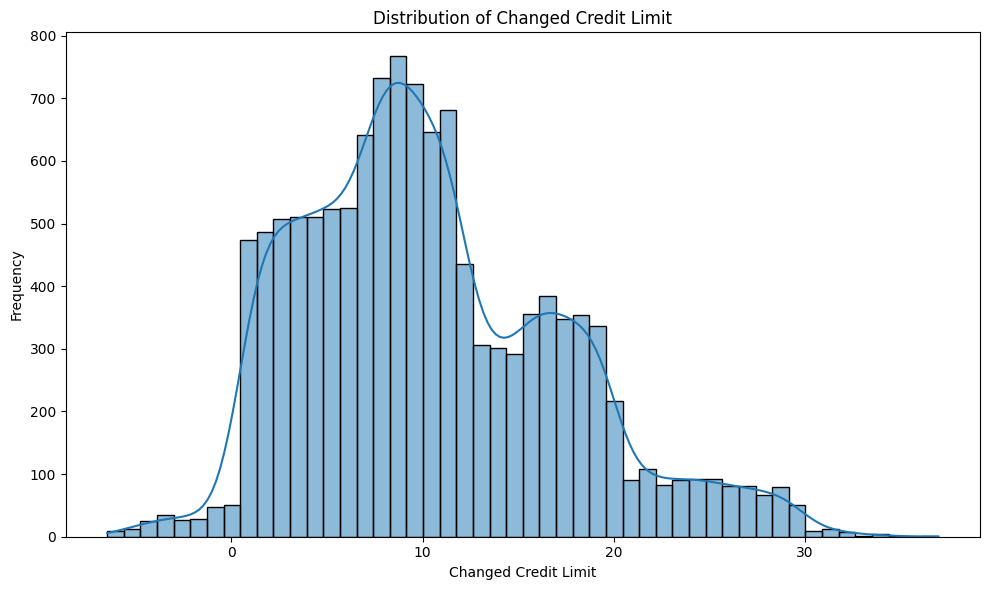

In [29]:
plt.figure(figsize=(10, 6))

sns.histplot(
    fs_pdf["Changed_Credit_Limit"],
    bins=50,
    kde=True
)

plt.title("Distribution of Changed Credit Limit")
plt.xlabel("Changed Credit Limit")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

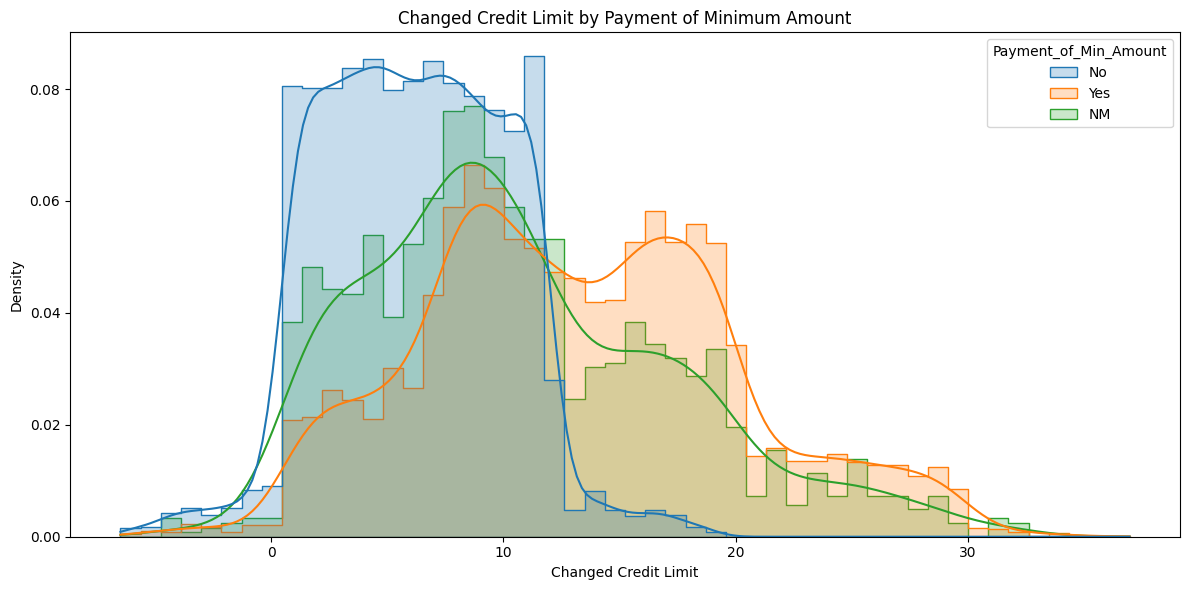

In [33]:
fs_pdf["Payment_of_Min_Amount"] = np.select(
    [
        fs_pdf["Payment_of_Min_Amount_NM"] == 1,
        fs_pdf["Payment_of_Min_Amount_No"] == 1,
        fs_pdf["Payment_of_Min_Amount_Yes"] == 1
    ],
    [
        "NM",
        "No",
        "Yes"
    ],
    default="Unknown"
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=fs_pdf,
    x="Changed_Credit_Limit",
    hue="Payment_of_Min_Amount",
    bins=50,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Changed Credit Limit by Payment of Minimum Amount")
plt.xlabel("Changed Credit Limit")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

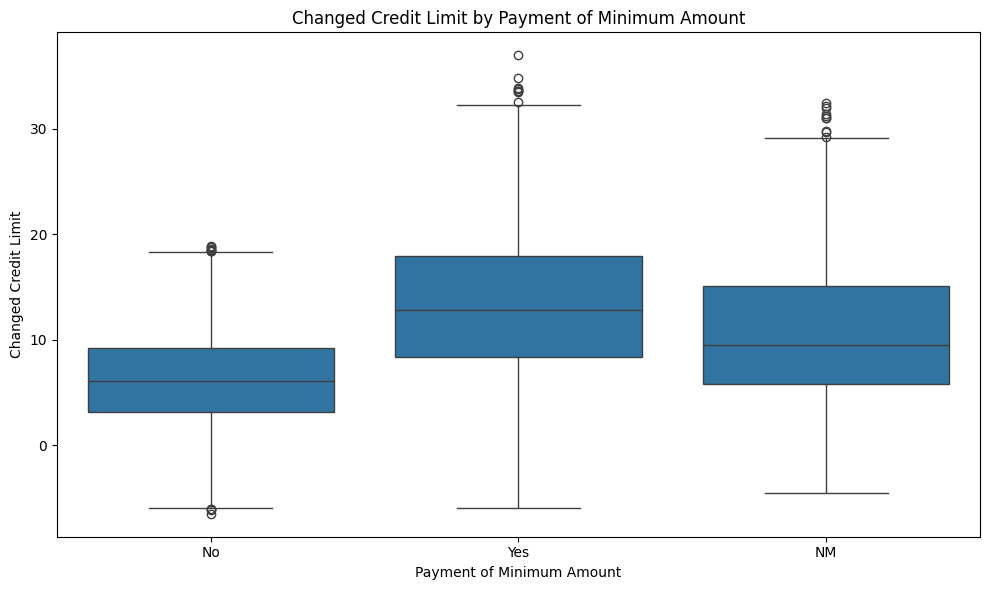

In [34]:
# Reconstruct Payment_of_Min_Amount category
fs_pdf["Payment_of_Min_Amount"] = np.select(
    [
        fs_pdf["Payment_of_Min_Amount_NM"] == 1,
        fs_pdf["Payment_of_Min_Amount_No"] == 1,
        fs_pdf["Payment_of_Min_Amount_Yes"] == 1
    ],
    [
        "NM",
        "No",
        "Yes"
    ],
    default="Unknown"
)

# Boxplot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=fs_pdf,
    x="Payment_of_Min_Amount",
    y="Changed_Credit_Limit"
)

plt.title("Changed Credit Limit by Payment of Minimum Amount")
plt.xlabel("Payment of Minimum Amount")
plt.ylabel("Changed Credit Limit")
plt.tight_layout()
plt.show()

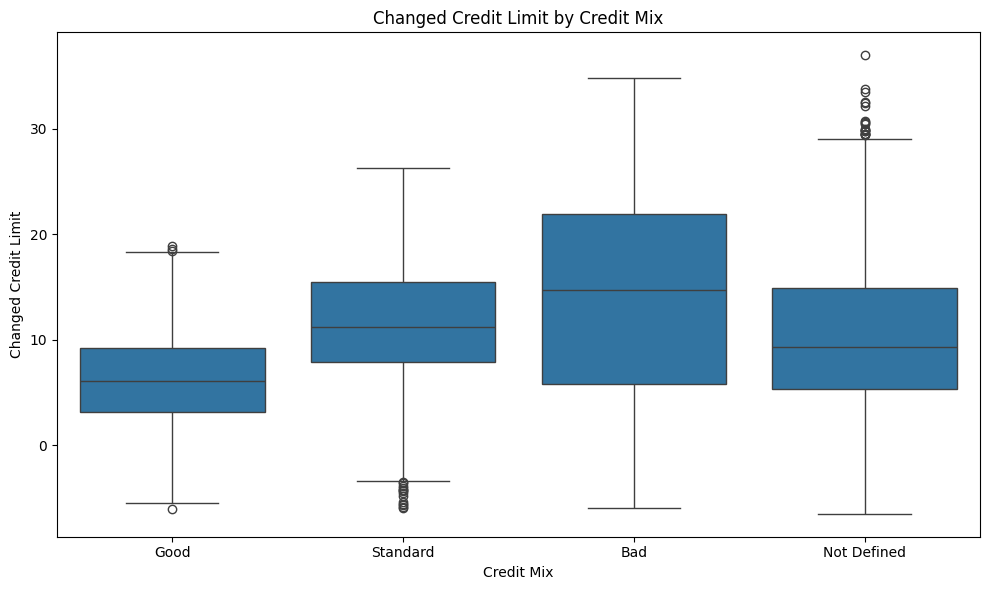

In [35]:
fs_pdf["Credit_Mix"] = np.select(
    [
        fs_pdf["Credit_Mix_Bad"] == 1,
        fs_pdf["Credit_Mix_Good"] == 1,
        fs_pdf["Credit_Mix_Standard"] == 1,
        fs_pdf["Credit_Mix_Not_Defined"] == 1
    ],
    [
        "Bad",
        "Good",
        "Standard",
        "Not Defined"
    ],
    default="Unknown"
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=fs_pdf,
    x="Credit_Mix",
    y="Changed_Credit_Limit"
)

plt.title("Changed Credit Limit by Credit Mix")
plt.xlabel("Credit Mix")
plt.ylabel("Changed Credit Limit")
plt.tight_layout()
plt.show()

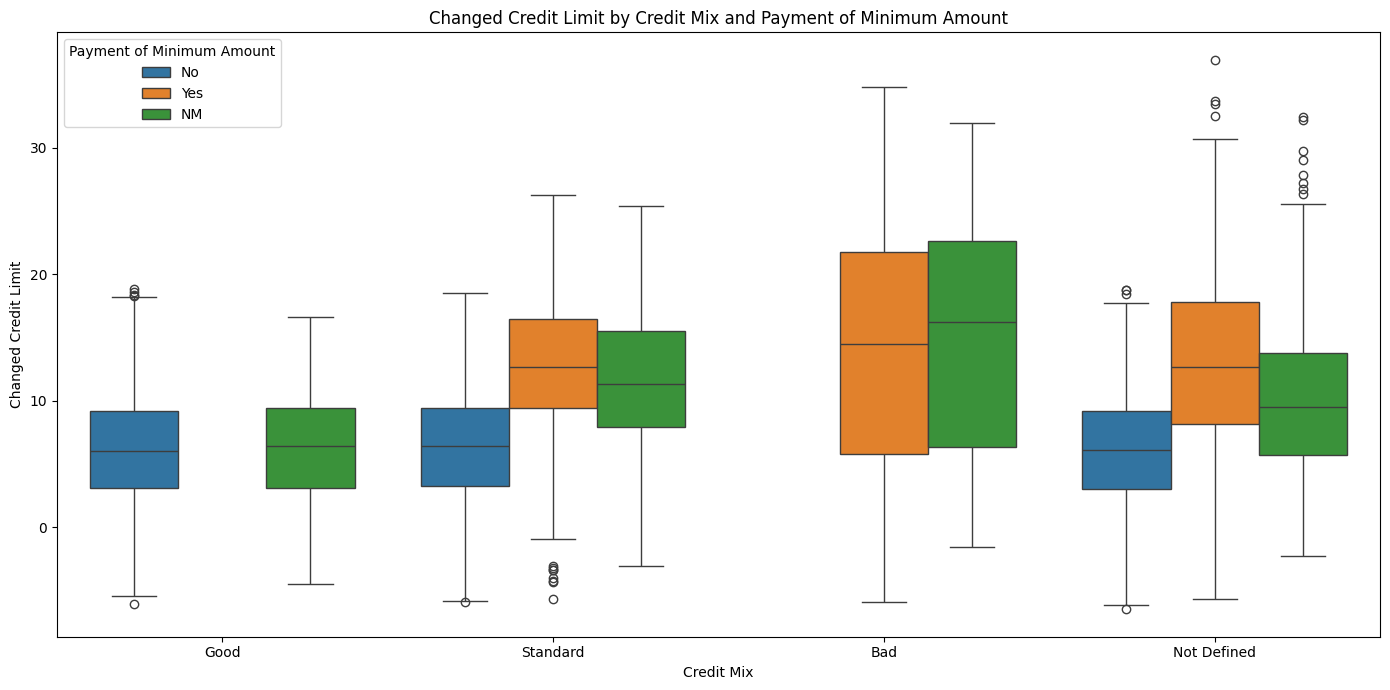

In [36]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=fs_pdf,
    x="Credit_Mix",
    y="Changed_Credit_Limit",
    hue="Payment_of_Min_Amount"
)

plt.title(
    "Changed Credit Limit by Credit Mix and Payment of Minimum Amount"
)

plt.xlabel("Credit Mix")
plt.ylabel("Changed Credit Limit")
plt.legend(
    title="Payment of Minimum Amount"
)

plt.tight_layout()
plt.show()

In [37]:
median_table = (
    fs_pdf
    .groupby(
        ["Credit_Mix", "Payment_of_Min_Amount"]
    )["Changed_Credit_Limit"]
    .agg(
        ["count", "median", "mean", "std"]
    )
    .reset_index()
)

display(median_table)

,Credit_Mix,Payment_of_Min_Amount,count,median,mean,std
0,Bad,NM,253,16.25,14.742253,9.120562
1,Bad,Yes,2053,14.49,13.988744,9.130708
2,Good,NM,331,6.43,6.323263,3.901842
3,Good,No,2637,6.01,6.199067,3.892796
4,Not Defined,NM,307,9.51,10.427525,6.594538
5,Not Defined,No,889,6.08,6.040563,4.009956
6,Not Defined,Yes,1364,12.66,13.110234,6.971656
7,Standard,NM,515,11.29,11.538194,5.207612
8,Standard,No,883,6.43,6.339218,3.892750
9,Standard,Yes,3014,12.67,12.760137,4.671725


In [6]:
label_sdf = spark.read.option("header","true").parquet('datamart/gold/label_store/gold_label_store_main_.parquet')
label_pdf = label_sdf.toPandas()
label_pdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   loan_id        12500 non-null  object
 1   Customer_ID    12500 non-null  object
 2   label          12500 non-null  int32 
 3   label_def      12500 non-null  object
 4   snapshot_date  12500 non-null  object
dtypes: int32(1), object(4)
memory usage: 439.6+ KB


In [7]:
clicks_silver_sdf = spark.read.option("header","true").parquet('datamart/silver/feature_clickstream/silver_clickstream_main_.parquet')
clicks_silver_pdf = clicks_silver_sdf.toPandas()

clicks_silver_pdf = clicks_silver_pdf.rename(
    columns={"snapshot_date": "clicks_snapshot_date"}
)
clicks_silver_pdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215376 entries, 0 to 215375
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   fe_1                  215376 non-null  int32 
 1   fe_2                  215376 non-null  int32 
 2   fe_3                  215376 non-null  int32 
 3   fe_4                  215376 non-null  int32 
 4   fe_5                  215376 non-null  int32 
 5   fe_6                  215376 non-null  int32 
 6   fe_7                  215376 non-null  int32 
 7   fe_8                  215376 non-null  int32 
 8   fe_9                  215376 non-null  int32 
 9   fe_10                 215376 non-null  int32 
 10  fe_11                 215376 non-null  int32 
 11  fe_12                 215376 non-null  int32 
 12  fe_13                 215376 non-null  int32 
 13  fe_14                 215376 non-null  int32 
 14  fe_15                 215376 non-null  int32 
 15  fe_16            

In [57]:
clicks_silver_pdf['Customer_ID'].nunique()

8974

In [56]:
labels = label_pdf.copy()
clicks = clicks_silver_pdf.copy()

key_cols = ["Customer_ID","snapshot_date"]

fe_cols = [f"fe_{i}" for i in range(1,21)]

# Convert dates to datetime
labels["snapshot_date"] = pd.to_datetime(
    labels["snapshot_date"]
)

clicks["clicks_snapshot_date"] = pd.to_datetime(
    clicks["clicks_snapshot_date"]
)

for col in fe_cols:
    clicks[col] = pd.to_numeric(clicks[col],errors="coerce")

clicks = clicks.drop_duplicates()


temp = clicks.merge(labels,on="Customer_ID",how="left")
display(temp.head())
print("length of temp df:", len(temp))
print("number of customers in temp df:", temp['Customer_ID'].nunique())

temp["days_before"] = (temp["snapshot_date"]- temp["clicks_snapshot_date"]).dt.days

filtered_temp = temp[temp["days_before"] > 0].copy() #    Only use clickstream information BEFORE snapshot_date

print("length of filtered temp df:", len(filtered_temp))
print("number of customers in filtered temp df:", filtered_temp['Customer_ID'].nunique())


display(filtered_temp.head())

,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date,loan_id,label,label_def,snapshot_date
0,133,66,-16,235,211,177,156,146,116,-82,62,154,-88,57,-16,118,21,254,-130,176,CUS_0x7de0,2023-05-01,CUS_0x7de0_2023_07_01,0,30dpd_6mob,2024-01-01
1,176,169,198,-95,168,-86,24,14,268,205,128,207,6,5,67,249,101,-55,119,282,CUS_0x7e0b,2023-05-01,CUS_0x7e0b_2023_07_01,1,30dpd_6mob,2024-01-01
2,122,-32,212,297,257,202,74,-72,296,102,173,13,-18,127,83,48,116,-11,97,96,CUS_0x7f50,2023-05-01,CUS_0x7f50_2023_07_01,0,30dpd_6mob,2024-01-01
3,-4,66,-2,-6,93,0,155,377,200,163,3,-164,127,-53,24,-134,203,174,126,170,CUS_0x7f9c,2023-05-01,CUS_0x7f9c_2023_07_01,0,30dpd_6mob,2024-01-01
4,125,29,-103,5,89,91,35,253,162,85,56,134,246,236,190,108,179,45,103,-100,CUS_0x8072,2023-05-01,CUS_0x8072_2023_07_01,0,30dpd_6mob,2024-01-01


length of temp df: 215376
number of customers in temp df: 8974
length of filtered temp df: 129778
number of customers in filtered temp df: 8974


,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date,loan_id,label,label_def,snapshot_date,days_before
0,133,66,-16,235,211,177,156,146,116,-82,62,154,-88,57,-16,118,21,254,-130,176,CUS_0x7de0,2023-05-01,CUS_0x7de0_2023_07_01,0,30dpd_6mob,2024-01-01,245
1,176,169,198,-95,168,-86,24,14,268,205,128,207,6,5,67,249,101,-55,119,282,CUS_0x7e0b,2023-05-01,CUS_0x7e0b_2023_07_01,1,30dpd_6mob,2024-01-01,245
2,122,-32,212,297,257,202,74,-72,296,102,173,13,-18,127,83,48,116,-11,97,96,CUS_0x7f50,2023-05-01,CUS_0x7f50_2023_07_01,0,30dpd_6mob,2024-01-01,245
3,-4,66,-2,-6,93,0,155,377,200,163,3,-164,127,-53,24,-134,203,174,126,170,CUS_0x7f9c,2023-05-01,CUS_0x7f9c_2023_07_01,0,30dpd_6mob,2024-01-01,245
4,125,29,-103,5,89,91,35,253,162,85,56,134,246,236,190,108,179,45,103,-100,CUS_0x8072,2023-05-01,CUS_0x8072_2023_07_01,0,30dpd_6mob,2024-01-01,245


In [47]:
# Function to calculate rolling mean features

windows = [30, 60, 90]

aggregation_methods = ["mean","median","max", "min","std"]

# Generic aggregation function
def create_aggregation_features(df,days,aggregation):
    subset = df[(df["days_before"] > 0) &(df["days_before"] <= days)].copy()
    # Apply aggregation
    result = (subset.groupby(["Customer_ID", "snapshot_date"])[fe_cols].agg(aggregation).reset_index())

    # Rename FE columns
    result = result.rename(columns={col: f"{col}_{aggregation}_{days}d" for col in fe_cols})

    return result

# Create all aggregation features

aggregation_dfs = {}

for aggregation in aggregation_methods:
    for days in windows:
        feature_name = f"{aggregation}_{days}d"
        aggregation_dfs[feature_name] = (create_aggregation_features(filtered_temp,days,aggregation))

        print(f"{feature_name}: " f"{len(aggregation_dfs[feature_name])} records")


# Create latest-value features Most recent clickstream observation before snapshot_date

latest = (filtered_temp.sort_values(["Customer_ID","snapshot_date","clicks_snapshot_date"])
    .groupby(["Customer_ID", "snapshot_date"])[fe_cols].last().reset_index())

latest = latest.rename(columns={col: f"{col}_latest" for col in fe_cols})

aggregation_dfs["latest"] = latest

# Function to calculate click counts

def create_count_features(df, days):
    subset = df[(df["days_before"] > 0) & (df["days_before"] <= days)].copy()
    result = (subset.groupby(["Customer_ID", "snapshot_date"]).size().reset_index(name=f"click_count_{days}d"))
    return result

# Create click counts
count_30d = create_count_features(filtered_temp,30)
count_60d = create_count_features(filtered_temp,60)
count_90d = create_count_features(filtered_temp,90)

aggregation_dfs["count_30d"] = count_30d
aggregation_dfs["count_60d"] = count_60d
aggregation_dfs["count_90d"] = count_90d

# Create 30-day trend
recent_30 = filtered_temp[(filtered_temp["days_before"] > 0) &(filtered_temp["days_before"] <= 30)].copy()

print('recent 30 day trend')
display(recent_30.head())

previous_30 = filtered_temp[(filtered_temp["days_before"] > 30) &(filtered_temp["days_before"] <= 60)].copy()

print('previous 30 day trend')
display(previous_30.head())

#recent 30 day averages
recent_avg = (recent_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean().reset_index())
recent_avg = recent_avg.rename(columns={col: f"{col}_recent_30d"for col in fe_cols})
print("number of records for recent_avg:", len(recent_avg))

# recent_avg = (recent_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean())
print('recent avg trend')
display(recent_avg.head())


# previous 30 day averages
previous_avg = (previous_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean().reset_index())
previous_avg = previous_avg.rename(columns={col: f"{col}_previous_30d"for col in fe_cols})
print("number of records for previous_avg:", len(previous_avg))

# previous_avg = (previous_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean())
print('previous avg trend')
display(previous_avg.head())

# calculate trend
trend = recent_avg.merge(previous_avg,on=["Customer_ID", "snapshot_date"],how="inner")

for col in fe_cols:
    trend[f"{col}_trend_30d"] = (trend[f"{col}_recent_30d"]- trend[f"{col}_previous_30d"])
trend = trend[["Customer_ID", "snapshot_date"]+ [f"{col}_trend_30d" for col in fe_cols]]
# trend = (recent_avg - previous_avg).reset_index()
# print('recent - previous trend reset index')
display(trend.head())
print("number of records for trend df:", len(trend))

trend = trend.rename(columns={col: f"{col}_trend_30d" for col in fe_cols})
# print('recent - previous trend')
# display(trend.head())

aggregation_dfs["trend_30d"] = trend

final_df = labels.copy()

for name, feature_df in aggregation_dfs.items():
    print(f"Merging {name}: " f"{feature_df.shape}")
    final_df = final_df.merge(feature_df,on=key_cols,how="left")

count_cols = ["click_count_30d","click_count_60d","click_count_90d"]

final_df[count_cols] = (final_df[count_cols].fillna(0).astype(int))

print("Final shape:", final_df.shape)
print("\nFeature columns:")
print([col for col in final_df.columns if col.startswith("fe_") or col.startswith("click_count")])

print("Sample:")
display(final_df.head())       

mean_30d: 3998 records
mean_60d: 8974 records
mean_90d: 8974 records
median_30d: 3998 records
median_60d: 8974 records
median_90d: 8974 records
max_30d: 3998 records
max_60d: 8974 records
max_90d: 8974 records
min_30d: 3998 records
min_60d: 8974 records
min_90d: 8974 records
std_30d: 3998 records
std_60d: 8974 records
std_90d: 8974 records
recent 30 day trend


,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date,loan_id,label,label_def,snapshot_date,days_before
657,145,108,78,-33,212,62,-46,135,-6,96,21,-9,-82,79,-72,184,114,281,-45,51,CUS_0x1037,2023-06-01,CUS_0x1037_2023_01_01,0,30dpd_6mob,2023-07-01,30
658,14,155,70,45,233,-121,174,159,3,154,18,141,119,275,116,166,154,81,75,163,CUS_0x1069,2023-06-01,CUS_0x1069_2023_01_01,0,30dpd_6mob,2023-07-01,30
659,305,197,101,-41,-30,60,266,66,110,-65,-35,22,67,103,-3,309,233,149,185,68,CUS_0x114a,2023-06-01,CUS_0x114a_2023_01_01,0,30dpd_6mob,2023-07-01,30
660,3,186,311,8,-105,124,62,89,160,70,136,92,185,62,135,104,66,1,152,200,CUS_0x1184,2023-06-01,CUS_0x1184_2023_01_01,0,30dpd_6mob,2023-07-01,30
661,311,241,25,29,133,247,-11,-20,-95,196,196,46,159,232,105,276,-53,131,153,-46,CUS_0x1297,2023-06-01,CUS_0x1297_2023_01_01,1,30dpd_6mob,2023-07-01,30


previous 30 day trend


,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date,loan_id,label,label_def,snapshot_date,days_before
13757,169,292,30,-93,215,113,102,74,133,90,99,71,-14,248,2,99,-51,161,94,337,CUS_0x10aa,2023-07-01,CUS_0x10aa_2023_02_01,0,30dpd_6mob,2023-08-01,31
13758,117,79,181,101,146,246,68,119,83,-32,66,203,122,-101,40,-114,269,54,194,39,CUS_0x113e,2023-07-01,CUS_0x113e_2023_02_01,1,30dpd_6mob,2023-08-01,31
13759,-103,72,77,180,171,12,154,61,74,22,43,157,177,195,-6,-10,-17,99,213,38,CUS_0x1140,2023-07-01,CUS_0x1140_2023_02_01,0,30dpd_6mob,2023-08-01,31
13760,302,80,151,165,60,-9,-53,59,263,238,121,49,159,8,-57,14,272,26,324,133,CUS_0x1155,2023-07-01,CUS_0x1155_2023_02_01,0,30dpd_6mob,2023-08-01,31
13761,58,168,129,-43,173,235,254,62,171,238,242,120,68,63,-31,-14,132,-9,-13,122,CUS_0x1252,2023-07-01,CUS_0x1252_2023_02_01,0,30dpd_6mob,2023-08-01,31


number of records for recent_avg: 3998
recent avg trend


...

number of records for previous_avg: 5430
previous avg trend


,Customer_ID,snapshot_date,fe_1_previous_30d,fe_2_previous_30d,fe_3_previous_30d,fe_4_previous_30d,fe_5_previous_30d,fe_6_previous_30d,fe_7_previous_30d,fe_8_previous_30d,fe_9_previous_30d,fe_10_previous_30d,fe_11_previous_30d,fe_12_previous_30d,fe_13_previous_30d,fe_14_previous_30d,fe_15_previous_30d,fe_16_previous_30d,fe_17_previous_30d,fe_18_previous_30d,fe_19_previous_30d,fe_20_previous_30d
0,CUS_0x1000,2023-11-01,150.0,212.0,146.0,189.0,-107.0,364.0,29.0,27.0,275.0,194.0,-91.0,82.0,-37.0,213.0,60.0,32.0,175.0,237.0,-195.0,66.0
1,CUS_0x100b,2024-09-01,247.0,99.0,82.0,66.0,9.0,140.0,127.0,190.0,-5.0,36.0,-34.0,150.0,221.0,3.0,3.0,81.0,144.0,48.0,38.0,226.0
2,CUS_0x1013,2024-06-01,147.0,153.0,200.0,81.0,226.0,93.0,231.0,182.0,50.0,196.0,30.0,125.0,3.0,55.0,42.0,265.0,246.0,114.0,12.0,189.0
3,CUS_0x1015,2024-02-01,242.0,111.0,187.0,-5.0,40.0,99.0,15.0,245.0,273.0,-35.0,160.0,226.0,201.0,-9.0,-16.0,148.0,35.0,82.0,6.0,-38.0
4,CUS_0x1026,2024-04-01,2.0,53.0,280.5,167.0,68.5,156.5,226.5,185.5,197.5,207.0,74.5,112.5,145.5,121.5,-5.0,138.0,166.0,33.0,152.5,156.5


,Customer_ID,snapshot_date,fe_1_trend_30d,fe_2_trend_30d,fe_3_trend_30d,fe_4_trend_30d,fe_5_trend_30d,fe_6_trend_30d,fe_7_trend_30d,fe_8_trend_30d,fe_9_trend_30d,fe_10_trend_30d,fe_11_trend_30d,fe_12_trend_30d,fe_13_trend_30d,fe_14_trend_30d,fe_15_trend_30d,fe_16_trend_30d,fe_17_trend_30d,fe_18_trend_30d,fe_19_trend_30d,fe_20_trend_30d
0,CUS_0x1057,2024-03-01,82.0,-193.0,-269.0,93.0,-37.0,-84.0,211.0,-72.0,47.0,43.0,147.0,-191.0,-10.0,277.0,16.0,95.0,-81.0,19.0,-60.0,-87.0
1,CUS_0x1169,2024-03-01,89.0,114.0,-3.0,91.0,9.0,27.0,-48.0,121.0,-152.0,-25.0,66.0,53.0,128.0,-40.0,-37.0,70.0,-154.0,-210.0,-7.0,131.0
2,CUS_0x117d,2024-03-01,-289.0,95.0,-202.0,-66.0,69.0,-5.0,311.0,303.0,183.0,-45.0,115.0,107.0,-262.0,373.0,170.0,-34.0,91.0,129.0,-59.0,70.0
3,CUS_0x1182,2024-03-01,56.0,-103.0,122.0,190.0,178.0,-20.0,-14.0,-33.0,-211.0,49.0,99.0,-50.0,-271.0,-43.0,-6.0,30.0,99.0,73.0,-237.0,94.0
4,CUS_0x11c6,2024-03-01,120.0,145.0,19.0,-277.0,-3.0,-140.0,-48.0,-39.0,-359.0,238.0,-95.0,-28.0,2.0,-244.0,109.0,-155.0,-90.0,67.0,86.0,-131.0


number of records for trend df: 454
Merging mean_30d: (3998, 22)
Merging mean_60d: (8974, 22)
Merging mean_90d: (8974, 22)
Merging median_30d: (3998, 22)
Merging median_60d: (8974, 22)
Merging median_90d: (8974, 22)
Merging max_30d: (3998, 22)
Merging max_60d: (8974, 22)
Merging max_90d: (8974, 22)
Merging min_30d: (3998, 22)
Merging min_60d: (8974, 22)
Merging min_90d: (8974, 22)
Merging std_30d: (3998, 22)
Merging std_60d: (8974, 22)
Merging std_90d: (8974, 22)
Merging latest: (8974, 22)
Merging count_30d: (3998, 3)
Merging count_60d: (8974, 3)
Merging count_90d: (8974, 3)
Merging trend_30d: (454, 22)
Final shape: (12500, 348)

Feature columns:
['fe_1_mean_30d', 'fe_2_mean_30d', 'fe_3_mean_30d', 'fe_4_mean_30d', 'fe_5_mean_30d', 'fe_6_mean_30d', 'fe_7_mean_30d', 'fe_8_mean_30d', 'fe_9_mean_30d', 'fe_10_mean_30d', 'fe_11_mean_30d', 'fe_12_mean_30d', 'fe_13_mean_30d', 'fe_14_mean_30d', 'fe_15_mean_30d', 'fe_16_mean_30d', 'fe_17_mean_30d', 'fe_18_mean_30d', 'fe_19_mean_30d', 'fe_20_mean

,loan_id,Customer_ID,label,label_def,snapshot_date,fe_1_mean_30d,fe_2_mean_30d,fe_3_mean_30d,fe_4_mean_30d,fe_5_mean_30d,fe_6_mean_30d,fe_7_mean_30d,fe_8_mean_30d,fe_9_mean_30d,fe_10_mean_30d,fe_11_mean_30d,fe_12_mean_30d,fe_13_mean_30d,fe_14_mean_30d,fe_15_mean_30d,fe_16_mean_30d,fe_17_mean_30d,fe_18_mean_30d,fe_19_mean_30d,fe_20_mean_30d,fe_1_mean_60d,fe_2_mean_60d,fe_3_mean_60d,fe_4_mean_60d,fe_5_mean_60d,fe_6_mean_60d,fe_7_mean_60d,fe_8_mean_60d,fe_9_mean_60d,fe_10_mean_60d,fe_11_mean_60d,fe_12_mean_60d,fe_13_mean_60d,fe_14_mean_60d,fe_15_mean_60d,fe_16_mean_60d,fe_17_mean_60d,fe_18_mean_60d,fe_19_mean_60d,fe_20_mean_60d,fe_1_mean_90d,fe_2_mean_90d,fe_3_mean_90d,fe_4_mean_90d,fe_5_mean_90d,fe_6_mean_90d,fe_7_mean_90d,fe_8_mean_90d,fe_9_mean_90d,fe_10_mean_90d,fe_11_mean_90d,fe_12_mean_90d,fe_13_mean_90d,fe_14_mean_90d,fe_15_mean_90d,fe_16_mean_90d,fe_17_mean_90d,fe_18_mean_90d,fe_19_mean_90d,fe_20_mean_90d,fe_1_median_30d,fe_2_median_30d,fe_3_median_30d,fe_4_median_30d,fe_5_median_30d,fe_6_median_30d,fe_7_median_30d,fe_8_median_30d,fe_9_median_30d,fe_10_median_30d,fe_11_median_30d,fe_12_median_30d,fe_13_median_30d,fe_14_median_30d,fe_15_median_30d,fe_16_median_30d,fe_17_median_30d,fe_18_median_30d,fe_19_median_30d,fe_20_median_30d,fe_1_median_60d,fe_2_median_60d,fe_3_median_60d,fe_4_median_60d,fe_5_median_60d,fe_6_median_60d,fe_7_median_60d,fe_8_median_60d,fe_9_median_60d,fe_10_median_60d,fe_11_median_60d,fe_12_median_60d,fe_13_median_60d,fe_14_median_60d,fe_15_median_60d,fe_16_median_60d,fe_17_median_60d,fe_18_median_60d,fe_19_median_60d,fe_20_median_60d,fe_1_median_90d,fe_2_median_90d,fe_3_median_90d,fe_4_median_90d,fe_5_median_90d,fe_6_median_90d,fe_7_median_90d,fe_8_median_90d,fe_9_median_90d,fe_10_median_90d,fe_11_median_90d,fe_12_median_90d,fe_13_median_90d,fe_14_median_90d,fe_15_median_90d,fe_16_median_90d,fe_17_median_90d,fe_18_median_90d,fe_19_median_90d,fe_20_median_90d,fe_1_max_30d,fe_2_max_30d,fe_3_max_30d,fe_4_max_30d,fe_5_max_30d,fe_6_max_30d,fe_7_max_30d,fe_8_max_30d,fe_9_max_30d,fe_10_max_30d,fe_11_max_30d,fe_12_max_30d,fe_13_max_30d,fe_14_max_30d,fe_15_max_30d,fe_16_max_30d,fe_17_max_30d,fe_18_max_30d,fe_19_max_30d,fe_20_max_30d,fe_1_max_60d,fe_2_max_60d,fe_3_max_60d,fe_4_max_60d,fe_5_max_60d,fe_6_max_60d,fe_7_max_60d,fe_8_max_60d,fe_9_max_60d,fe_10_max_60d,fe_11_max_60d,fe_12_max_60d,fe_13_max_60d,fe_14_max_60d,fe_15_max_60d,fe_16_max_60d,fe_17_max_60d,fe_18_max_60d,fe_19_max_60d,fe_20_max_60d,fe_1_max_90d,fe_2_max_90d,fe_3_max_90d,fe_4_max_90d,fe_5_max_90d,fe_6_max_90d,fe_7_max_90d,fe_8_max_90d,fe_9_max_90d,fe_10_max_90d,fe_11_max_90d,fe_12_max_90d,fe_13_max_90d,fe_14_max_90d,fe_15_max_90d,fe_16_max_90d,fe_17_max_90d,fe_18_max_90d,fe_19_max_90d,fe_20_max_90d,fe_1_min_30d,fe_2_min_30d,fe_3_min_30d,fe_4_min_30d,fe_5_min_30d,fe_6_min_30d,fe_7_min_30d,fe_8_min_30d,fe_9_min_30d,fe_10_min_30d,fe_11_min_30d,fe_12_min_30d,fe_13_min_30d,fe_14_min_30d,fe_15_min_30d,fe_16_min_30d,fe_17_min_30d,fe_18_min_30d,fe_19_min_30d,fe_20_min_30d,fe_1_min_60d,fe_2_min_60d,fe_3_min_60d,fe_4_min_60d,fe_5_min_60d,fe_6_min_60d,fe_7_min_60d,fe_8_min_60d,fe_9_min_60d,fe_10_min_60d,fe_11_min_60d,fe_12_min_60d,fe_13_min_60d,fe_14_min_60d,fe_15_min_60d,fe_16_min_60d,fe_17_min_60d,fe_18_min_60d,fe_19_min_60d,fe_20_min_60d,fe_1_min_90d,fe_2_min_90d,fe_3_min_90d,fe_4_min_90d,fe_5_min_90d,fe_6_min_90d,fe_7_min_90d,fe_8_min_90d,fe_9_min_90d,fe_10_min_90d,fe_11_min_90d,fe_12_min_90d,fe_13_min_90d,fe_14_min_90d,fe_15_min_90d,fe_16_min_90d,fe_17_min_90d,fe_18_min_90d,fe_19_min_90d,fe_20_min_90d,fe_1_std_30d,fe_2_std_30d,fe_3_std_30d,fe_4_std_30d,fe_5_std_30d,fe_6_std_30d,fe_7_std_30d,fe_8_std_30d,fe_9_std_30d,fe_10_std_30d,fe_11_std_30d,fe_12_std_30d,fe_13_std_30d,fe_14_std_30d,fe_15_std_30d,fe_16_std_30d,fe_17_std_30d,fe_18_std_30d,fe_19_std_30d,fe_20_std_30d,fe_1_std_60d,fe_2_std_60d,fe_3_std_60d,fe_4_std_60d,fe_5_std_60d,fe_6_std_60d,fe_7_std_60d,fe_8_std_60d,fe_9_std_60d,fe_10_std_60d,fe_11_std_60d,fe_12_std_60d,fe_13_std_60d,fe_14_std_60d

In [54]:
aggregation_cols = [
    col for col in final_df.columns
    if (col.startswith("fe_")
        and (
            "_latest" in col
            or "_mean_" in col
            or "_median_" in col
            or "_max_" in col
            or "_min_" in col
            or "_std_" in col
            or "_trend_" in col))]

print("Number of aggregation features:",len(aggregation_cols))

# Calculate correlation with label

correlations = []

for col in aggregation_cols:
    temp_corr = final_df[[col, "label"]].dropna()
    if temp_corr[col].nunique() <= 1:
        corr = np.nan
    else:
        corr = temp_corr[col].corr(
            temp_corr["label"]
        )

    correlations.append({
        "Feature": col,
        "Correlation": corr,
        "Abs_Correlation": abs(corr) if pd.notna(corr) else np.nan
    })


corr_df = pd.DataFrame(correlations)

# Sort by absolute correlation
corr_df = corr_df.sort_values(
    "Abs_Correlation",
    ascending=False
).reset_index(drop=True)

display(corr_df.head(60))

Number of aggregation features: 340


,Feature,Correlation,Abs_Correlation
0,fe_10_mean_90d,-0.177087,0.177087
1,fe_10_median_90d,-0.175240,0.175240
2,fe_5_median_90d,0.164104,0.164104
3,fe_5_mean_90d,0.163508,0.163508
4,fe_10_max_90d,-0.152372,0.152372
5,fe_10_min_90d,-0.149570,0.149570
6,fe_5_min_90d,0.142955,0.142955
7,fe_10_min_30d,-0.140722,0.140722
8,fe_10_median_30d,-0.140722,0.140722
9,fe_10_max_30d,-0.140722,0.140722


Feature_Type,Latest
Feature,
fe_1,0.0032
fe_10,-0.1230
fe_11,-0.0001
fe_12,0.0096
fe_13,-0.0014
fe_14,0.0052
fe_15,0.0029
fe_16,0.0096
fe_17,-0.0013


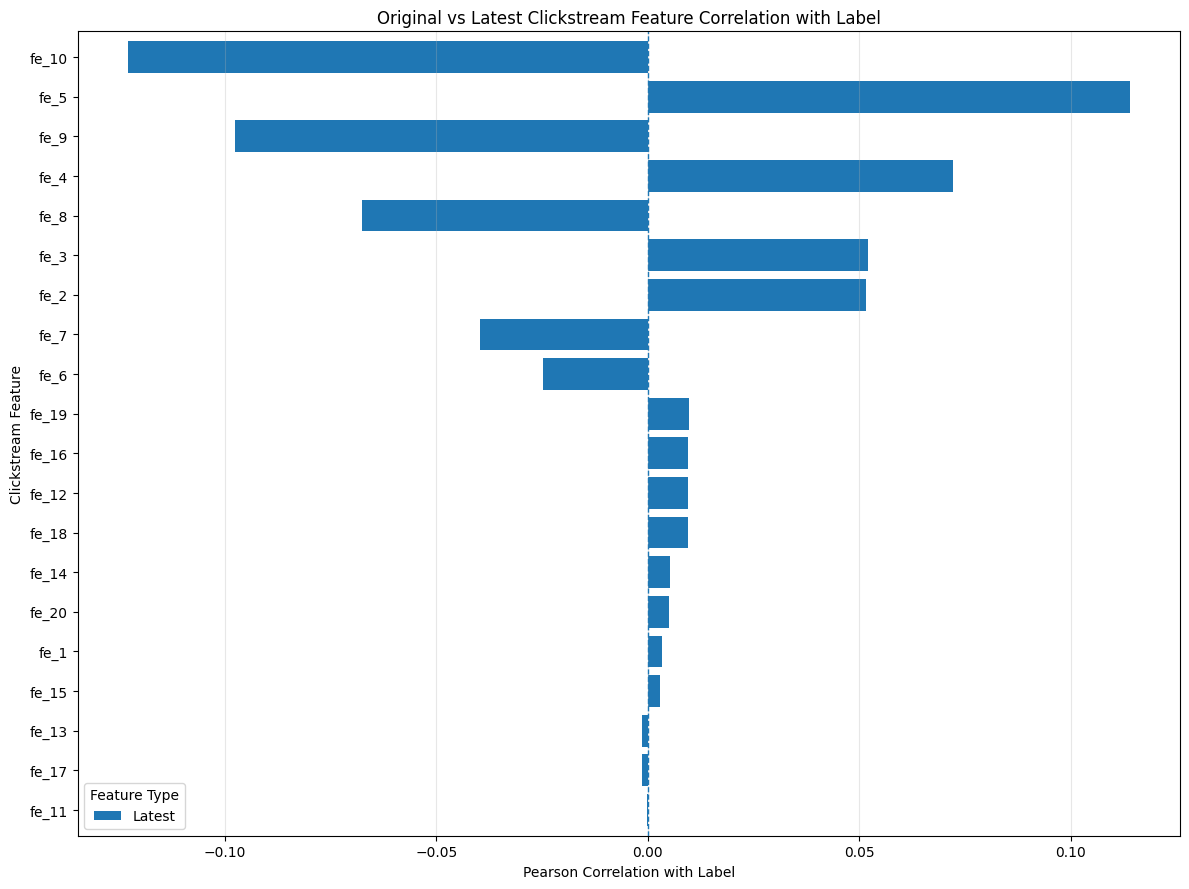

In [48]:
results = []

for col in fe_cols:
    latest_col = f"{col}_latest"

    for feature_type, feature_col in [
        ("Original", col),
        ("Latest", latest_col)
    ]:
        if feature_col not in final_df.columns:
            continue

        temp = final_df[[feature_col, "label"]].dropna()

        if len(temp) < 2 or temp[feature_col].nunique() <= 1:
            corr = np.nan
        else:
            corr = temp[feature_col].corr(temp["label"])

        results.append({
            "Feature": col,
            "Feature_Type": feature_type,
            "Correlation": corr,
            "Abs_Correlation": abs(corr) if pd.notna(corr) else np.nan
        })

corr_plot_df = pd.DataFrame(results)

# View the correlation table
display(
    corr_plot_df.pivot(
        index="Feature",
        columns="Feature_Type",
        values="Correlation"
    ).round(4)
)

# ============================================================
# 2. Plot grouped bar chart
# ============================================================

plot_df = corr_plot_df.pivot(
    index="Feature",
    columns="Feature_Type",
    values="Correlation"
)

# Sort by the strongest absolute correlation across both types
plot_df = plot_df.loc[
    plot_df.abs().max(axis=1).sort_values(ascending=True).index
]

ax = plot_df.plot(
    kind="barh",
    figsize=(12, 9),
    width=0.8
)

ax.axvline(0, linewidth=1, linestyle="--")
ax.set_title("Original vs Latest Clickstream Feature Correlation with Label")
ax.set_xlabel("Pearson Correlation with Label")
ax.set_ylabel("Clickstream Feature")
ax.legend(title="Feature Type")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

Labels shape: (12500, 5)
Filtered clickstream shape: (129778, 27)
Final aggregated DataFrame shape: (12500, 348)

Latest raw clickstream shape: (8974, 27)

Correlation comparison:


,Feature,fe_x,Valid_Rows,fe_x_latest,Latest_Valid_Rows,Feature_Number
0,fe_1,0.003243,8974,0.003243,8974,1
1,fe_2,0.051640,8974,0.051640,8974,2
2,fe_3,0.051984,8974,0.051984,8974,3
3,fe_4,0.072129,8974,0.072129,8974,4
4,fe_5,0.113976,8974,0.113976,8974,5
5,fe_6,-0.024899,8974,-0.024899,8974,6
6,fe_7,-0.039580,8974,-0.039580,8974,7
7,fe_8,-0.067683,8974,-0.067683,8974,8
8,fe_9,-0.097502,8974,-0.097502,8974,9
9,fe_10,-0.123000,8974,-0.123000,8974,10


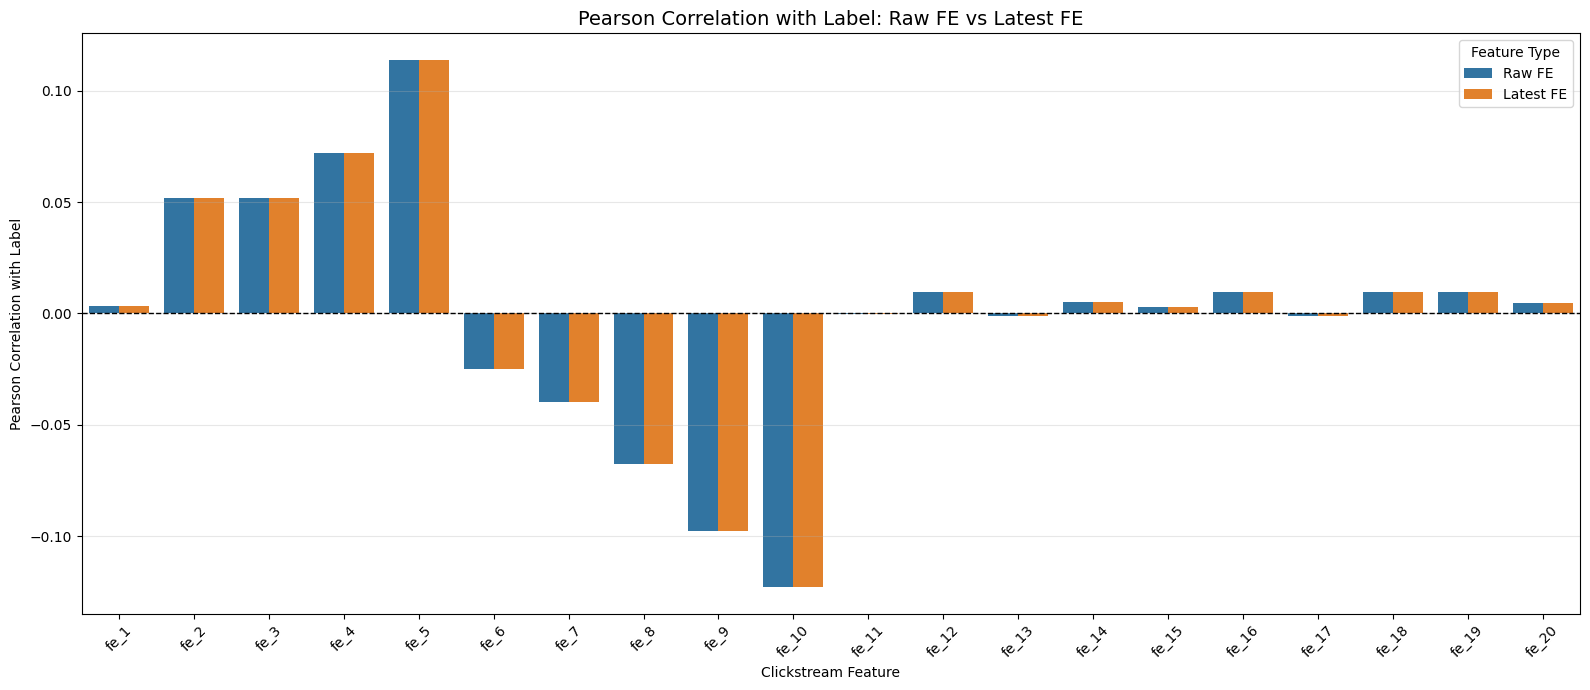


Features ranked by absolute latest-value correlation:


,Feature,fe_x,fe_x_latest,Valid_Rows,Latest_Valid_Rows
9,fe_10,-0.123000,-0.123000,8974,8974
4,fe_5,0.113976,0.113976,8974,8974
8,fe_9,-0.097502,-0.097502,8974,8974
3,fe_4,0.072129,0.072129,8974,8974
7,fe_8,-0.067683,-0.067683,8974,8974
2,fe_3,0.051984,0.051984,8974,8974
1,fe_2,0.051640,0.051640,8974,8974
6,fe_7,-0.039580,-0.039580,8974,8974
5,fe_6,-0.024899,-0.024899,8974,8974
18,fe_19,0.009845,0.009845,8974,8974


In [52]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. Define clickstream feature columns
# ============================================================

fe_cols = [f"fe_{i}" for i in range(1, 21)]

key_cols = ["Customer_ID", "snapshot_date"]

print("Labels shape:", labels.shape)
print("Filtered clickstream shape:", filtered_temp.shape)
print("Final aggregated DataFrame shape:", final_df.shape)


# ============================================================
# 2. Function to calculate Pearson correlations with label
# ============================================================

def calculate_label_correlations(
    df,
    feature_cols,
    label_col="label"
):
    results = []

    for col in feature_cols:

        if col not in df.columns:
            continue

        if label_col not in df.columns:
            raise KeyError(
                f"'{label_col}' not found in DataFrame. "
                f"Available columns: {df.columns.tolist()}"
            )

        temp = df[[col, label_col]].copy()

        temp[col] = pd.to_numeric(temp[col], errors="coerce")
        temp[label_col] = pd.to_numeric(
            temp[label_col], errors="coerce"
        )

        temp = temp.replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        if len(temp) < 2 or temp[col].nunique() <= 1:
            corr = np.nan
        else:
            corr = temp[col].corr(temp[label_col])

        results.append({
            "Feature": col,
            "Correlation": corr,
            "Valid_Rows": len(temp)
        })

    return pd.DataFrame(results)


# ============================================================
# 3. Calculate correlations for raw clickstream features
#    using the latest historical observation per snapshot
# ============================================================

# Ensure label is present in filtered_temp.
# Your displayed columns confirm that it already exists.
if "label" not in filtered_temp.columns:

    label_df = (
        labels[key_cols + ["label"]]
        .drop_duplicates(key_cols)
    )

    raw_source = filtered_temp.merge(
        label_df,
        on=key_cols,
        how="left",
        validate="many_to_one"
    )

else:
    raw_source = filtered_temp.copy()


# Keep only observations strictly before the label snapshot.
raw_source = raw_source[
    raw_source["days_before"] > 0
].copy()


# Sort chronologically so tail(1) selects the latest
# clickstream observation before each label snapshot.
raw_latest = (
    raw_source
    .sort_values(
        ["Customer_ID", "snapshot_date", "clicks_snapshot_date"]
    )
    .groupby(key_cols)
    .tail(1)
    .copy()
)

print("\nLatest raw clickstream shape:", raw_latest.shape)

raw_cols = [
    col for col in fe_cols
    if col in raw_latest.columns
]

raw_corr = calculate_label_correlations(
    raw_latest,
    raw_cols,
    label_col="label"
)

raw_corr = raw_corr.rename(
    columns={"Correlation": "fe_x"}
)

raw_corr = raw_corr[["Feature", "fe_x", "Valid_Rows"]]


# ============================================================
# 4. Calculate correlations for aggregated latest features
# ============================================================

latest_cols = [
    f"{col}_latest"
    for col in fe_cols
    if f"{col}_latest" in final_df.columns
]

latest_corr = calculate_label_correlations(
    final_df,
    latest_cols,
    label_col="label"
)

# Convert names such as fe_1_latest back to fe_1
latest_corr["Feature"] = latest_corr["Feature"].str.extract(
    r"(fe_\d+)", expand=False
)

latest_corr = latest_corr.rename(
    columns={
        "Correlation": "fe_x_latest",
        "Valid_Rows": "Latest_Valid_Rows"
    }
)

latest_corr = latest_corr[
    ["Feature", "fe_x_latest", "Latest_Valid_Rows"]
]


# ============================================================
# 5. Combine correlation results
# ============================================================

comparison = raw_corr.merge(
    latest_corr,
    on="Feature",
    how="outer"
)

comparison["Feature_Number"] = (
    comparison["Feature"]
    .str.extract(r"fe_(\d+)", expand=False)
    .astype(int)
)

comparison = (
    comparison
    .sort_values("Feature_Number")
    .reset_index(drop=True)
)

print("\nCorrelation comparison:")
display(comparison)


# ============================================================
# 6. Reshape data for plotting
# ============================================================

comparison_long = comparison.melt(
    id_vars=["Feature", "Feature_Number"],
    value_vars=["fe_x", "fe_x_latest"],
    var_name="Feature_Type",
    value_name="Correlation"
)

comparison_long["Feature_Type"] = (
    comparison_long["Feature_Type"]
    .map({
        "fe_x": "Raw FE",
        "fe_x_latest": "Latest FE"
    })
)

feature_order = comparison["Feature"].tolist()


# ============================================================
# 7. Plot side-by-side correlations
# ============================================================

plt.figure(figsize=(16, 7))

ax = sns.barplot(
    data=comparison_long,
    x="Feature",
    y="Correlation",
    hue="Feature_Type",
    hue_order=["Raw FE", "Latest FE"],
    order=feature_order
)

ax.axhline(
    0,
    color="black",
    linewidth=1,
    linestyle="--"
)

ax.set_title(
    "Pearson Correlation with Label: Raw FE vs Latest FE",
    fontsize=14
)

ax.set_xlabel("Clickstream Feature")
ax.set_ylabel("Pearson Correlation with Label")

ax.tick_params(axis="x", rotation=45)
ax.legend(title="Feature Type")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 8. Optional: rank features by absolute correlation
# ============================================================

comparison["Abs_Correlation_Raw"] = comparison["fe_x"].abs()
comparison["Abs_Correlation_Latest"] = (
    comparison["fe_x_latest"].abs()
)

ranked_comparison = comparison.sort_values(
    "Abs_Correlation_Latest",
    ascending=False
)

print("\nFeatures ranked by absolute latest-value correlation:")
display(
    ranked_comparison[
        [
            "Feature",
            "fe_x",
            "fe_x_latest",
            "Valid_Rows",
            "Latest_Valid_Rows"
        ]
    ]
)


In [51]:
print("labels columns:", labels.columns.tolist())
print("filtered_temp columns:", filtered_temp.columns.tolist())
print("final_df columns:", final_df.columns.tolist())

labels columns: ['loan_id', 'Customer_ID', 'label', 'label_def', 'snapshot_date']
filtered_temp columns: ['fe_1', 'fe_2', 'fe_3', 'fe_4', 'fe_5', 'fe_6', 'fe_7', 'fe_8', 'fe_9', 'fe_10', 'fe_11', 'fe_12', 'fe_13', 'fe_14', 'fe_15', 'fe_16', 'fe_17', 'fe_18', 'fe_19', 'fe_20', 'Customer_ID', 'clicks_snapshot_date', 'loan_id', 'label', 'label_def', 'snapshot_date', 'days_before']
final_df columns: ['loan_id', 'Customer_ID', 'label', 'label_def', 'snapshot_date', 'fe_1_mean_30d', 'fe_2_mean_30d', 'fe_3_mean_30d', 'fe_4_mean_30d', 'fe_5_mean_30d', 'fe_6_mean_30d', 'fe_7_mean_30d', 'fe_8_mean_30d', 'fe_9_mean_30d', 'fe_10_mean_30d', 'fe_11_mean_30d', 'fe_12_mean_30d', 'fe_13_mean_30d', 'fe_14_mean_30d', 'fe_15_mean_30d', 'fe_16_mean_30d', 'fe_17_mean_30d', 'fe_18_mean_30d', 'fe_19_mean_30d', 'fe_20_mean_30d', 'fe_1_mean_60d', 'fe_2_mean_60d', 'fe_3_mean_60d', 'fe_4_mean_60d', 'fe_5_mean_60d', 'fe_6_mean_60d', 'fe_7_mean_60d', 'fe_8_mean_60d', 'fe_9_mean_60d', 'fe_10_mean_60d', 'fe_11_mean_6

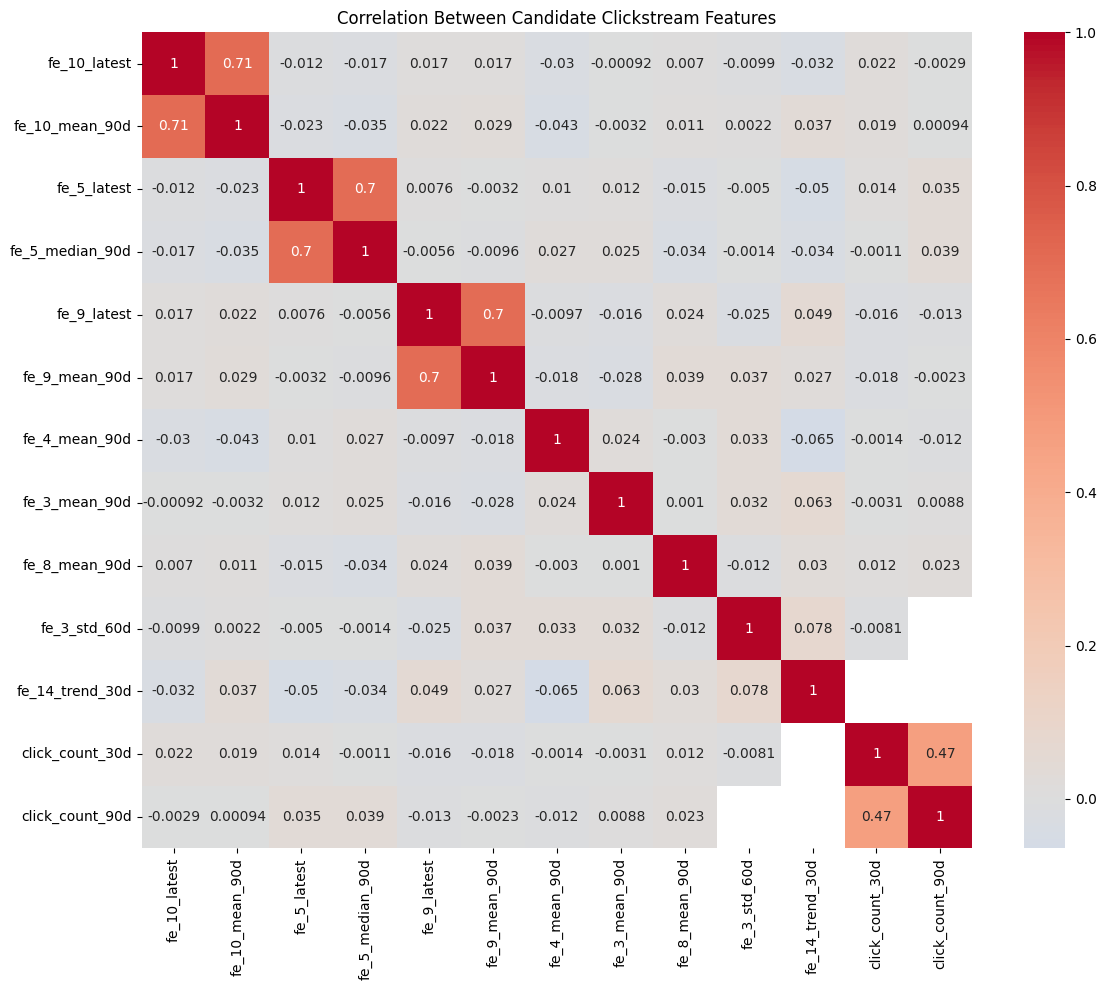

In [24]:
candidate_features = [
    "fe_10_latest",
    "fe_10_mean_90d",
    "fe_5_latest",
    "fe_5_median_90d",
    "fe_9_latest",
    "fe_9_mean_90d",
    "fe_4_mean_90d",
    "fe_3_mean_90d",
    "fe_8_mean_90d",
    "fe_3_std_60d",
    "fe_14_trend_30d",
    "click_count_30d",
    "click_count_90d"
]

corr = final_df[candidate_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True
)
plt.title("Correlation Between Candidate Clickstream Features")
plt.tight_layout()
plt.show()

In [21]:
final_df.head()

,loan_id,Customer_ID,label,label_def,snapshot_date,fe_1_mean_30d,fe_2_mean_30d,fe_3_mean_30d,fe_4_mean_30d,fe_5_mean_30d,fe_6_mean_30d,fe_7_mean_30d,fe_8_mean_30d,fe_9_mean_30d,fe_10_mean_30d,fe_11_mean_30d,fe_12_mean_30d,fe_13_mean_30d,fe_14_mean_30d,fe_15_mean_30d,fe_16_mean_30d,fe_17_mean_30d,fe_18_mean_30d,fe_19_mean_30d,fe_20_mean_30d,fe_1_mean_60d,fe_2_mean_60d,fe_3_mean_60d,fe_4_mean_60d,fe_5_mean_60d,fe_6_mean_60d,fe_7_mean_60d,fe_8_mean_60d,fe_9_mean_60d,fe_10_mean_60d,fe_11_mean_60d,fe_12_mean_60d,fe_13_mean_60d,fe_14_mean_60d,fe_15_mean_60d,fe_16_mean_60d,fe_17_mean_60d,fe_18_mean_60d,fe_19_mean_60d,fe_20_mean_60d,fe_1_mean_90d,fe_2_mean_90d,fe_3_mean_90d,fe_4_mean_90d,fe_5_mean_90d,fe_6_mean_90d,fe_7_mean_90d,fe_8_mean_90d,fe_9_mean_90d,fe_10_mean_90d,fe_11_mean_90d,fe_12_mean_90d,fe_13_mean_90d,fe_14_mean_90d,fe_15_mean_90d,fe_16_mean_90d,fe_17_mean_90d,fe_18_mean_90d,fe_19_mean_90d,fe_20_mean_90d,fe_1_median_30d,fe_2_median_30d,fe_3_median_30d,fe_4_median_30d,fe_5_median_30d,fe_6_median_30d,fe_7_median_30d,fe_8_median_30d,fe_9_median_30d,fe_10_median_30d,fe_11_median_30d,fe_12_median_30d,fe_13_median_30d,fe_14_median_30d,fe_15_median_30d,fe_16_median_30d,fe_17_median_30d,fe_18_median_30d,fe_19_median_30d,fe_20_median_30d,fe_1_median_60d,fe_2_median_60d,fe_3_median_60d,fe_4_median_60d,fe_5_median_60d,fe_6_median_60d,fe_7_median_60d,fe_8_median_60d,fe_9_median_60d,fe_10_median_60d,fe_11_median_60d,fe_12_median_60d,fe_13_median_60d,fe_14_median_60d,fe_15_median_60d,fe_16_median_60d,fe_17_median_60d,fe_18_median_60d,fe_19_median_60d,fe_20_median_60d,fe_1_median_90d,fe_2_median_90d,fe_3_median_90d,fe_4_median_90d,fe_5_median_90d,fe_6_median_90d,fe_7_median_90d,fe_8_median_90d,fe_9_median_90d,fe_10_median_90d,fe_11_median_90d,fe_12_median_90d,fe_13_median_90d,fe_14_median_90d,fe_15_median_90d,fe_16_median_90d,fe_17_median_90d,fe_18_median_90d,fe_19_median_90d,fe_20_median_90d,fe_1_max_30d,fe_2_max_30d,fe_3_max_30d,fe_4_max_30d,fe_5_max_30d,fe_6_max_30d,fe_7_max_30d,fe_8_max_30d,fe_9_max_30d,fe_10_max_30d,fe_11_max_30d,fe_12_max_30d,fe_13_max_30d,fe_14_max_30d,fe_15_max_30d,fe_16_max_30d,fe_17_max_30d,fe_18_max_30d,fe_19_max_30d,fe_20_max_30d,fe_1_max_60d,fe_2_max_60d,fe_3_max_60d,fe_4_max_60d,fe_5_max_60d,fe_6_max_60d,fe_7_max_60d,fe_8_max_60d,fe_9_max_60d,fe_10_max_60d,fe_11_max_60d,fe_12_max_60d,fe_13_max_60d,fe_14_max_60d,fe_15_max_60d,fe_16_max_60d,fe_17_max_60d,fe_18_max_60d,fe_19_max_60d,fe_20_max_60d,fe_1_max_90d,fe_2_max_90d,fe_3_max_90d,fe_4_max_90d,fe_5_max_90d,fe_6_max_90d,fe_7_max_90d,fe_8_max_90d,fe_9_max_90d,fe_10_max_90d,fe_11_max_90d,fe_12_max_90d,fe_13_max_90d,fe_14_max_90d,fe_15_max_90d,fe_16_max_90d,fe_17_max_90d,fe_18_max_90d,fe_19_max_90d,fe_20_max_90d,fe_1_min_30d,fe_2_min_30d,fe_3_min_30d,fe_4_min_30d,fe_5_min_30d,fe_6_min_30d,fe_7_min_30d,fe_8_min_30d,fe_9_min_30d,fe_10_min_30d,fe_11_min_30d,fe_12_min_30d,fe_13_min_30d,fe_14_min_30d,fe_15_min_30d,fe_16_min_30d,fe_17_min_30d,fe_18_min_30d,fe_19_min_30d,fe_20_min_30d,fe_1_min_60d,fe_2_min_60d,fe_3_min_60d,fe_4_min_60d,fe_5_min_60d,fe_6_min_60d,fe_7_min_60d,fe_8_min_60d,fe_9_min_60d,fe_10_min_60d,fe_11_min_60d,fe_12_min_60d,fe_13_min_60d,fe_14_min_60d,fe_15_min_60d,fe_16_min_60d,fe_17_min_60d,fe_18_min_60d,fe_19_min_60d,fe_20_min_60d,fe_1_min_90d,fe_2_min_90d,fe_3_min_90d,fe_4_min_90d,fe_5_min_90d,fe_6_min_90d,fe_7_min_90d,fe_8_min_90d,fe_9_min_90d,fe_10_min_90d,fe_11_min_90d,fe_12_min_90d,fe_13_min_90d,fe_14_min_90d,fe_15_min_90d,fe_16_min_90d,fe_17_min_90d,fe_18_min_90d,fe_19_min_90d,fe_20_min_90d,fe_1_std_30d,fe_2_std_30d,fe_3_std_30d,fe_4_std_30d,fe_5_std_30d,fe_6_std_30d,fe_7_std_30d,fe_8_std_30d,fe_9_std_30d,fe_10_std_30d,fe_11_std_30d,fe_12_std_30d,fe_13_std_30d,fe_14_std_30d,fe_15_std_30d,fe_16_std_30d,fe_17_std_30d,fe_18_std_30d,fe_19_std_30d,fe_20_std_30d,fe_1_std_60d,fe_2_std_60d,fe_3_std_60d,fe_4_std_60d,fe_5_std_60d,fe_6_std_60d,fe_7_std_60d,fe_8_std_60d,fe_9_std_60d,fe_10_std_60d,fe_11_std_60d,fe_12_std_60d,fe_13_std_60d,fe_14_std_60d

Original aggregation features: 340
Features usable for PCA: 320
Removed: 20

Missing values:
fe_4_trend_30d     12046
fe_3_trend_30d     12046
fe_2_trend_30d     12046
fe_1_trend_30d     12046
fe_8_trend_30d     12046
fe_7_trend_30d     12046
fe_6_trend_30d     12046
fe_5_trend_30d     12046
fe_20_trend_30d    12046
fe_19_trend_30d    12046
fe_18_trend_30d    12046
fe_17_trend_30d    12046
fe_16_trend_30d    12046
fe_15_trend_30d    12046
fe_14_trend_30d    12046
fe_13_trend_30d    12046
fe_12_trend_30d    12046
fe_11_trend_30d    12046
fe_10_trend_30d    12046
fe_9_trend_30d     12046
dtype: int64


,Component,Explained_Variance,Cumulative_Variance
0,1,0.031562,0.031562
1,2,0.031294,0.062855
2,3,0.031003,0.093858
3,4,0.030679,0.124537
4,5,0.030444,0.154981
...,...,...,...
315,316,0.000000,1.000000
316,317,0.000000,1.000000
317,318,0.000000,1.000000
318,319,0.000000,1.000000


70% variance: 37 components
80% variance: 54 components
85% variance: 65 components
90% variance: 80 components
95% variance: 99 components
99% variance: 117 components


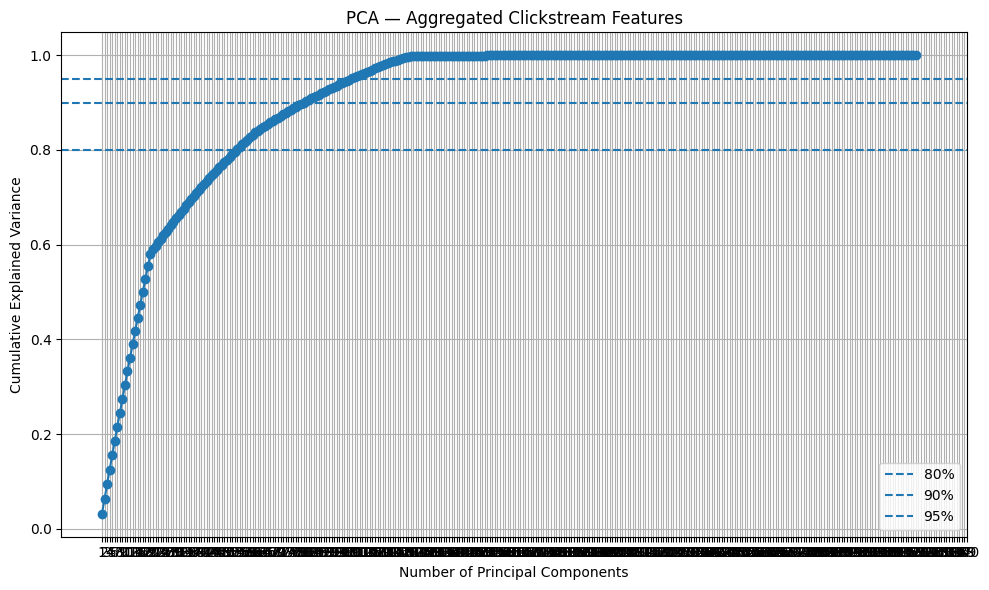


n_components: 1
Explained variance by each component: [0.0316]
Cumulative explained variance: 0.0316

n_components: 2
Explained variance by each component: [0.0316 0.0313]
Cumulative explained variance: 0.0629

n_components: 3
Explained variance by each component: [0.0316 0.0313 0.031 ]
Cumulative explained variance: 0.0939

n_components: 4
Explained variance by each component: [0.0316 0.0313 0.031  0.0307]
Cumulative explained variance: 0.1245

n_components: 5
Explained variance by each component: [0.0316 0.0313 0.031  0.0307 0.0304]
Cumulative explained variance: 0.155

n_components: 6
Explained variance by each component: [0.0316 0.0313 0.031  0.0307 0.0304 0.0302]
Cumulative explained variance: 0.1851

n_components: 7
Explained variance by each component: [0.0316 0.0313 0.031  0.0307 0.0304 0.0302 0.03  ]
Cumulative explained variance: 0.2151

n_components: 8
Explained variance by each component: [0.0316 0.0313 0.031  0.0307 0.0304 0.0302 0.03   0.0295]
Cumulative explained varian

In [40]:
# ============================================================
# 3. Prepare data for PCA
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Remove features that are completely missing
aggregation_cols_pca = [
    col for col in aggregation_cols
    if final_df[col].notna().any()
]

print(
    "Original aggregation features:",
    len(aggregation_cols)
)

print(
    "Features usable for PCA:",
    len(aggregation_cols_pca)
)

print(
    "Removed:",
    len(aggregation_cols) - len(aggregation_cols_pca)
)


X = final_df[aggregation_cols_pca].copy()

# Check missing values
print("\nMissing values:")
print(X.isna().sum().sort_values(ascending=False).head(20))


# ============================================================
# 4. Median imputation
# ============================================================
# For exploratory PCA.
# For the final model, calculate these medians from TRAIN only.

X = X.fillna(X.median())


# ============================================================
# 5. Standardise the features
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================================
# 6. Fit PCA with ALL components
# ============================================================

pca_full = PCA()

X_pca_full = pca_full.fit_transform(X_scaled)


# ============================================================
# 7. Explained variance
# ============================================================

pca_summary = pd.DataFrame({
    "Component": range(
        1,
        len(pca_full.explained_variance_ratio_) + 1
    ),
    "Explained_Variance": pca_full.explained_variance_ratio_,
    "Cumulative_Variance": np.cumsum(
        pca_full.explained_variance_ratio_
    )
})

display(pca_summary)


# ============================================================
# 8. Find number of components for common thresholds
# ============================================================

for threshold in [0.70, 0.80, 0.85, 0.90, 0.95, 0.99]:

    n_components = np.argmax(
        pca_summary["Cumulative_Variance"].values >= threshold
    ) + 1

    print(
        f"{threshold:.0%} variance: "
        f"{n_components} components"
    )


# ============================================================
# 9. Plot cumulative explained variance
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    pca_summary["Component"],
    pca_summary["Cumulative_Variance"],
    marker="o"
)

plt.axhline(
    0.80,
    linestyle="--",
    label="80%"
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90%"
)

plt.axhline(
    0.95,
    linestyle="--",
    label="95%"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title(
    "PCA — Aggregated Clickstream Features"
)

plt.xticks(
    range(1, len(aggregation_cols) + 1)
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Test different numbers of PCA components
# ============================================================

max_components_to_test = min(
    20,
    len(aggregation_cols)
)

for i in range(1, max_components_to_test + 1):

    pca = PCA(n_components=i)

    pca_features = pca.fit_transform(X_scaled)

    print(
        f"\nn_components: {i}"
    )

    print(
        "Explained variance by each component:",
        np.round(
            pca.explained_variance_ratio_,
            4
        )
    )

    print(
        "Cumulative explained variance:",
        round(
            pca.explained_variance_ratio_.sum(),
            4
        )
    )

# Behavioural 
fe_10_mean_90d
fe_5_median_90d
fe_9_mean_90d
fe_4_mean_90d
fe_3_mean_90d
fe_8_mean_90d

Recency:
fe_10_latest
fe_5_latest
fe_9_latest

# Behavioural frequency
click_count_30d
click_count_60d
click_count_90d

In [17]:
aggregation_cols = fe_cols
print("Number of aggregation features:",len(aggregation_cols))

# Calculate correlation with label

correlations = []

for col in aggregation_cols:
    temp_corr = filtered_temp[[col, "label"]].dropna()
    if temp_corr[col].nunique() <= 1:
        corr = np.nan
    else:
        corr = temp_corr[col].corr(
            temp_corr["label"]
        )

    correlations.append({
        "Feature": col,
        "Correlation": corr,
        "Abs_Correlation": abs(corr) if pd.notna(corr) else np.nan
    })


corr_df = pd.DataFrame(correlations)

# Sort by absolute correlation
corr_df = corr_df.sort_values(
    "Abs_Correlation",
    ascending=False
).reset_index(drop=True)

display(corr_df.head(30))


Number of aggregation features: 20


,Feature,Correlation,Abs_Correlation
0,fe_10,-0.111853,0.111853
1,fe_5,0.108667,0.108667
2,fe_9,-0.088865,0.088865
3,fe_4,0.088853,0.088853
4,fe_3,0.070192,0.070192
5,fe_8,-0.068209,0.068209
6,fe_2,0.045575,0.045575
7,fe_7,-0.043693,0.043693
8,fe_1,0.023078,0.023078
9,fe_6,-0.019258,0.019258


In [ ]:
# Function to calculate rolling mean features


windows = [7, 30, 90]

aggregation_methods = ["mean","median","max", "min","std"]


# Generic aggregation function

def create_aggregation_features(df,days,aggregation):
    subset = df[(df["days_before"] > 0) &(df["days_before"] <= days)].copy()
    # Apply aggregation
    result = (subset.groupby(["Customer_ID", "snapshot_date"])[fe_cols].agg(aggregation).reset_index())

    # Rename FE columns
    result = result.rename(
        columns={col: f"{col}_{aggregation}_{days}d" for col in fe_cols})

    return result

# Create all aggregation features

aggregation_dfs = {}

for aggregation in aggregation_methods:
    for days in windows:
        feature_name = f"{aggregation}_{days}d"
        aggregation_dfs[feature_name] = (create_aggregation_features(filtered_temp,days,aggregation))

        print(f"{feature_name}: " f"{len(aggregation_dfs[feature_name])} records")

def create_mean_features(df, days):
    subset = df[(df["days_before"] > 0) & (df["days_before"] <= days)].copy()
    result = (subset.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean().reset_index())
    result = result.rename(columns={col: f"{col}_mean_{days}d" for col in fe_cols})
    return result


# Create 7 / 30 / 90 day mean features

mean_7d = create_mean_features(filtered_temp,7)
mean_30d = create_mean_features(filtered_temp,30)
mean_90d = create_mean_features(filtered_temp,90)


# Create latest-value features Most recent clickstream observation before snapshot_date


latest = (filtered_temp.sort_values(["Customer_ID","snapshot_date","clicks_snapshot_date"])
    .groupby(["Customer_ID", "snapshot_date"])[fe_cols].last().reset_index())

latest = latest.rename(columns={col: f"{col}_latest" for col in fe_cols})

aggregation_dfs["latest"] = latest

# Function to calculate click counts

def create_count_features(df, days):
    subset = df[(df["days_before"] > 0) & (df["days_before"] <= days)].copy()
    result = (subset.groupby(["Customer_ID", "snapshot_date"]).size().reset_index(name=f"click_count_{days}d"))
    return result

# Create click counts
count_7d = create_count_features(filtered_temp,7)
count_30d = create_count_features(filtered_temp,30)
count_90d = create_count_features(filtered_temp,90)

# Create 30-day trend
recent_30 = filtered_temp[(filtered_temp["days_before"] > 0) &(filtered_temp["days_before"] <= 30)].copy()

print('recent 30 day trend')
display(recent_30.head())

previous_30 = filtered_temp[(filtered_temp["days_before"] > 30) &(filtered_temp["days_before"] <= 60)].copy()

print('previous 30 day trend')
display(previous_30.head())

#recent 30 day averages
# recent_avg = (recent_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean().reset_index())
# recent_avg = recent_avg.rename(columns={col: f"{col}_recent_30d"for col in fe_cols})
# print("number of records for recent_avg:", len(recent_avg))

recent_avg = (recent_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean())
print('recent avg trend')
display(recent_avg.head())


# # previous 30 day averages
# previous_avg = (previous_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean().reset_index())
# previous_avg = previous_avg.rename(columns={col: f"{col}_previous_30d"for col in fe_cols})
# print("number of records for previous_avg:", len(previous_avg))

previous_avg = (previous_30.groupby(["Customer_ID", "snapshot_date"])[fe_cols].mean())
print('previous avg trend')
display(previous_avg.head())

# calculate trend
trend = recent_avg.merge(previous_avg,on=["Customer_ID", "snapshot_date"],how="inner")

for col in fe_cols:
    trend[f"{col}_trend_30d"] = (trend[f"{col}_recent_30d"]- trend[f"{col}_previous_30d"])
trend = trend[["Customer_ID", "snapshot_date"]+ [f"{col}_trend_30d" for col in fe_cols]]
# trend = (recent_avg - previous_avg).reset_index()
# print('recent - previous trend reset index')
display(trend.head())
print("number of records for trend df:", len(trend))

trend = trend.rename(columns={col: f"{col}_trend_30d" for col in fe_cols})
# print('recent - previous trend')
# display(trend.head())

aggregation_dfs["trend_30d"] = trend

final_df = labels.copy()


for name, feature_df in aggregation_dfs.items():
    print(f"Merging {name}: " f"{feature_df.shape}")

    final_df = final_df.merge(feature_df,on=key_cols,how="left")



final_df[count_cols] = (final_df[count_cols].fillna(0).astype(int))

print("Final shape:", final_df.shape)
print("\nFeature columns:")
print([col for col in final_df.columns if col.startswith("fe_") or col.startswith("click_count")])

print("Sample:")
display(final_df.head()) 

In [ ]:
# Merge latest features
final_df = final_df.merge(latest,on = key_cols,how="left")
# Merge 7-day mean features
final_df = final_df.merge(mean_7d,on=key_cols,how="left")
#  Merge 30-day mean features      
final_df = final_df.merge(mean_30d,on=key_cols,how="left")
#  Merge 90-day mean features      
final_df = final_df.merge(mean_90d,on=key_cols,how="left")

# Merge click counts
final_df = final_df.merge(count_7d,on=key_cols,how="left")
final_df = final_df.merge(count_30d,on=key_cols,how="left")
final_df = final_df.merge(count_90d,on=key_cols,how="left")
# Merge Tends
final_df = final_df.merge(trend,on=key_cols,how="left")

count_cols = ["click_count_7d","click_count_30d","click_count_90d"]
# Fill click counts with 0. No clickstream record in the window means zero observations.

In [80]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Columns: 348 entries, loan_id to fe_20_trend_30d
dtypes: datetime64[ns](1), float64(340), int32(1), int64(3), object(3)
memory usage: 33.1+ MB


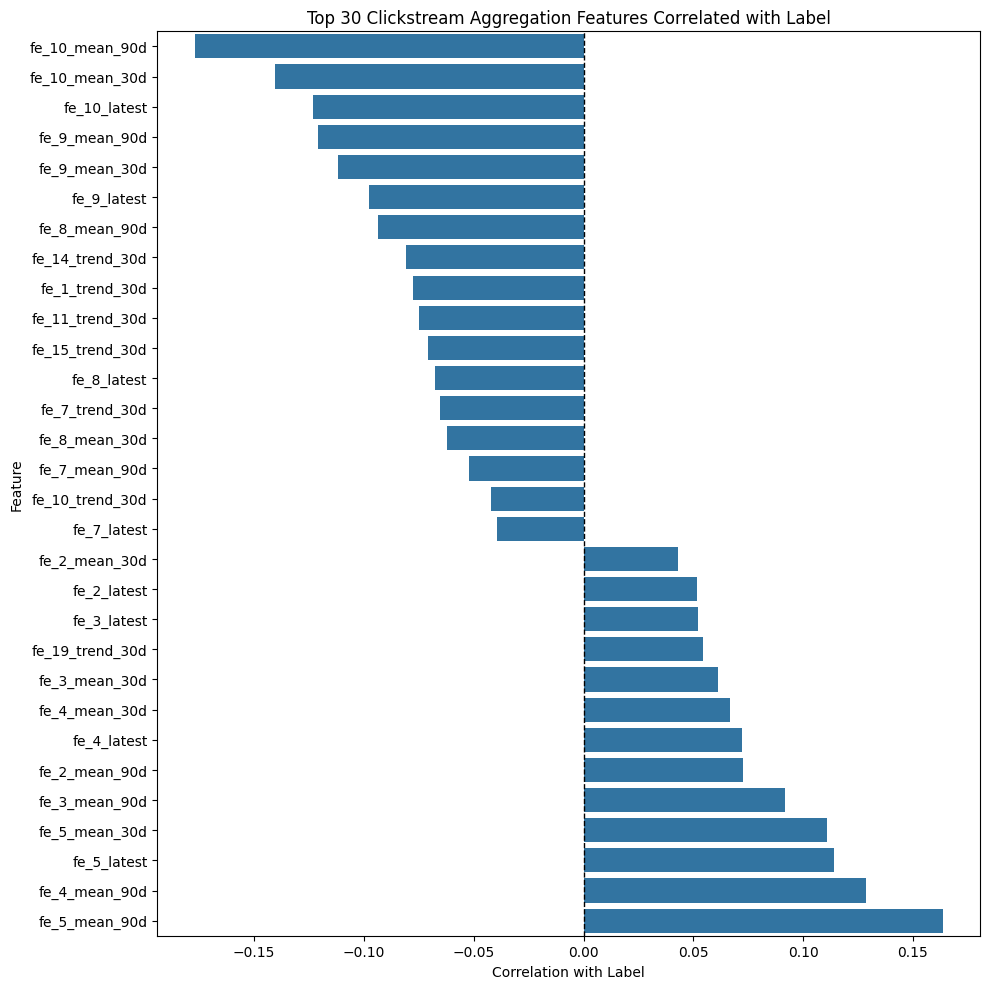

In [72]:
top_n = 30

plot_df = corr_df.head(top_n).sort_values("Correlation")

plt.figure(figsize=(10, 10))
sns.barplot(data=plot_df,x="Correlation",y="Feature")
plt.axvline(0,color="black",linestyle="--",linewidth=1)

plt.title(f"Top {top_n} Clickstream Aggregation Features Correlated with Label")

plt.xlabel("Correlation with Label")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

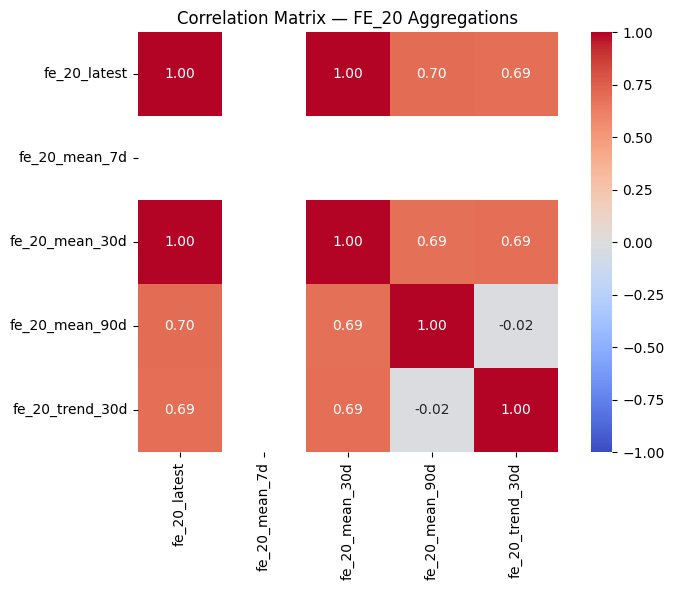

In [74]:
for i in range(1, 21):

    cols = [f"fe_{i}_latest",f"fe_{i}_mean_7d",f"fe_{i}_mean_30d",f"fe_{i}_mean_90d",f"fe_{i}_trend_30d"]
    
    # Keep only columns that actually exist
    cols = [col for col in cols if col in final_df.columns]

corr_matrix = final_df[cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1,square=True)

plt.title(f"Correlation Matrix — FE_{i} Aggregations")

plt.tight_layout()
plt.show()

In [42]:
merged_df1 = clicks_silver_pdf.merge(
    label_pdf,
    left_on=["Customer_ID"],
    right_on=["Customer_ID"],
    how="left"
)
merged_df1.head()

,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date,loan_id,label,label_def,snapshot_date
0,133,66,-16,235,211,177,156,146,116,-82,62,154,-88,57,-16,118,21,254,-130,176,CUS_0x7de0,2023-05-01,CUS_0x7de0_2023_07_01,0,30dpd_6mob,2024-01-01
1,176,169,198,-95,168,-86,24,14,268,205,128,207,6,5,67,249,101,-55,119,282,CUS_0x7e0b,2023-05-01,CUS_0x7e0b_2023_07_01,1,30dpd_6mob,2024-01-01
2,122,-32,212,297,257,202,74,-72,296,102,173,13,-18,127,83,48,116,-11,97,96,CUS_0x7f50,2023-05-01,CUS_0x7f50_2023_07_01,0,30dpd_6mob,2024-01-01
3,-4,66,-2,-6,93,0,155,377,200,163,3,-164,127,-53,24,-134,203,174,126,170,CUS_0x7f9c,2023-05-01,CUS_0x7f9c_2023_07_01,0,30dpd_6mob,2024-01-01
4,125,29,-103,5,89,91,35,253,162,85,56,134,246,236,190,108,179,45,103,-100,CUS_0x8072,2023-05-01,CUS_0x8072_2023_07_01,0,30dpd_6mob,2024-01-01


In [37]:
merged_df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215376 entries, 0 to 215375
Data columns (total 26 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   fe_1             215376 non-null  int32 
 1   fe_2             215376 non-null  int32 
 2   fe_3             215376 non-null  int32 
 3   fe_4             215376 non-null  int32 
 4   fe_5             215376 non-null  int32 
 5   fe_6             215376 non-null  int32 
 6   fe_7             215376 non-null  int32 
 7   fe_8             215376 non-null  int32 
 8   fe_9             215376 non-null  int32 
 9   fe_10            215376 non-null  int32 
 10  fe_11            215376 non-null  int32 
 11  fe_12            215376 non-null  int32 
 12  fe_13            215376 non-null  int32 
 13  fe_14            215376 non-null  int32 
 14  fe_15            215376 non-null  int32 
 15  fe_16            215376 non-null  int32 
 16  fe_17            215376 non-null  int32 
 17  fe_18     

In [43]:
merged_df1.describe()

,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,label
count,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000,215376.000000
mean,101.414796,103.096195,104.333709,105.648503,106.996676,103.235922,107.070337,110.718724,114.406354,117.775797,99.615537,99.823680,100.420804,100.025801,99.600383,99.860834,100.129425,100.125139,100.341162,100.046259,0.288723
std,99.833594,99.930002,100.599865,100.326065,100.693607,100.270388,100.323265,100.243698,100.186139,100.807686,100.335428,100.591175,100.881826,101.070371,101.145906,100.751876,101.298428,102.231587,102.666804,103.589358,0.453170
min,-378.000000,-356.000000,-399.000000,-307.000000,-343.000000,-321.000000,-368.000000,-361.000000,-328.000000,-317.000000,-375.000000,-344.000000,-355.000000,-394.000000,-351.000000,-342.000000,-329.000000,-344.000000,-401.000000,-354.000000,0.000000
25%,34.000000,36.000000,36.000000,38.000000,39.000000,36.000000,39.000000,43.000000,47.000000,50.000000,32.000000,32.000000,33.000000,32.000000,31.000000,32.000000,32.000000,31.000000,31.000000,30.000000,0.000000
50%,102.000000,103.000000,104.000000,106.000000,107.000000,103.000000,107.000000,111.000000,115.000000,118.000000,100.000000,100.000000,101.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.000000
75%,169.000000,171.000000,172.000000,173.000000,175.000000,171.000000,174.000000,179.000000,182.000000,186.000000,167.000000,168.000000,168.000000,168.000000,168.000000,168.000000,169.000000,169.000000,170.000000,170.000000,1.000000
max,541.000000,560.000000,583.000000,562.000000,570.000000,565.000000,537.000000,573.000000,577.000000,537.000000,613.000000,550.000000,530.000000,583.000000,597.000000,554.000000,516.000000,551.000000,560.000000,547.000000,1.000000


In [45]:
merged_df1['Customer_ID'].nunique()

8974

In [47]:
# Keep only historical clickstream records
historical_clicks = merged_df1[
    merged_df1["clicks_snapshot_date"] < merged_df1["snapshot_date"]
]
historical_clicks.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129778 entries, 0 to 202552
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   fe_1                  129778 non-null  int32 
 1   fe_2                  129778 non-null  int32 
 2   fe_3                  129778 non-null  int32 
 3   fe_4                  129778 non-null  int32 
 4   fe_5                  129778 non-null  int32 
 5   fe_6                  129778 non-null  int32 
 6   fe_7                  129778 non-null  int32 
 7   fe_8                  129778 non-null  int32 
 8   fe_9                  129778 non-null  int32 
 9   fe_10                 129778 non-null  int32 
 10  fe_11                 129778 non-null  int32 
 11  fe_12                 129778 non-null  int32 
 12  fe_13                 129778 non-null  int32 
 13  fe_14                 129778 non-null  int32 
 14  fe_15                 129778 non-null  int32 
 15  fe_16                 

In [50]:
fe_cols = [f"fe_{i}" for i in range(1,21)]

fe_agg = (
    historical_clicks
    .groupby(["Customer_ID", "snapshot_date"])[fe_cols]
    .mean()
    .reset_index()
)

fe_agg.head()

,Customer_ID,snapshot_date,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20
0,CUS_0x1000,2023-11-01,111.500000,143.300000,138.600000,59.000000,130.600000,148.200000,143.100000,119.600000,148.300000,72.100000,107.200000,94.700000,61.500000,108.400000,89.000000,80.700000,54.000000,120.900000,85.800000,68.600000
1,CUS_0x100b,2024-09-01,127.300000,76.050000,97.600000,76.350000,78.650000,101.650000,124.350000,95.600000,114.350000,138.250000,115.100000,110.950000,115.700000,113.650000,115.050000,77.400000,94.250000,92.700000,134.150000,115.700000
2,CUS_0x1011,2024-05-01,114.312500,107.125000,76.562500,100.187500,61.750000,115.250000,142.187500,108.187500,120.312500,132.625000,54.812500,87.437500,106.250000,124.812500,137.625000,67.750000,128.562500,70.750000,118.500000,92.750000
3,CUS_0x1013,2024-06-01,94.882353,84.882353,96.588235,79.470588,86.235294,142.823529,152.941176,100.764706,116.058824,183.000000,60.588235,82.882353,103.882353,51.529412,69.176471,143.294118,84.705882,103.117647,99.117647,113.705882
4,CUS_0x1015,2024-02-01,50.923077,121.076923,78.230769,75.692308,115.538462,110.000000,160.461538,141.384615,106.000000,162.384615,89.230769,102.000000,115.000000,37.076923,156.769231,93.307692,113.538462,147.461538,105.384615,113.923077


In [39]:
merged_df = label_pdf.merge(
    clicks_silver_pdf,
    left_on=["Customer_ID", "snapshot_date"],
    right_on=["Customer_ID", "snapshot_date"],
    how="left"
)
merged_df.head()

,loan_id,Customer_ID,label,label_def,snapshot_date,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20
0,CUS_0x5002_2023_04_01,CUS_0x5002,1,30dpd_6mob,2023-10-01,152.0,248.0,217.0,137.0,12.0,167.0,130.0,-148.0,241.0,54.0,199.0,62.0,53.0,80.0,30.0,152.0,94.0,70.0,98.0,81.0
1,CUS_0x500d_2024_12_01,CUS_0x500d,1,30dpd_6mob,2025-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CUS_0x5012_2023_11_01,CUS_0x5012,1,30dpd_6mob,2024-05-01,59.0,195.0,194.0,137.0,39.0,69.0,57.0,179.0,42.0,134.0,54.0,82.0,4.0,103.0,55.0,-2.0,-18.0,118.0,6.0,34.0
3,CUS_0x501c_2024_03_01,CUS_0x501c,1,30dpd_6mob,2024-09-01,-15.0,4.0,317.0,153.0,59.0,94.0,-163.0,-32.0,28.0,16.0,-91.0,291.0,32.0,102.0,63.0,140.0,83.0,157.0,107.0,14.0
4,CUS_0x501d_2024_02_01,CUS_0x501d,0,30dpd_6mob,2024-08-01,-126.0,-21.0,215.0,115.0,118.0,42.0,242.0,234.0,225.0,259.0,220.0,51.0,207.0,237.0,219.0,191.0,22.0,140.0,168.0,192.0


In [40]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   loan_id        12500 non-null  object 
 1   Customer_ID    12500 non-null  object 
 2   label          12500 non-null  int32  
 3   label_def      12500 non-null  object 
 4   snapshot_date  12500 non-null  object 
 5   fe_1           8974 non-null   float64
 6   fe_2           8974 non-null   float64
 7   fe_3           8974 non-null   float64
 8   fe_4           8974 non-null   float64
 9   fe_5           8974 non-null   float64
 10  fe_6           8974 non-null   float64
 11  fe_7           8974 non-null   float64
 12  fe_8           8974 non-null   float64
 13  fe_9           8974 non-null   float64
 14  fe_10          8974 non-null   float64
 15  fe_11          8974 non-null   float64
 16  fe_12          8974 non-null   float64
 17  fe_13          8974 non-null   float64
 18  fe_14 

In [24]:
merged_na = merged_df[merged_df.isna().any(axis = 1)]
merged_na.head()

,loan_id,Customer_ID,label,label_def,snapshot_date,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,clicks_snapshot_date
1,CUS_0x500d_2024_12_01,CUS_0x500d,1,30dpd_6mob,2025-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,CUS_0x503f_2025_01_01,CUS_0x503f,0,30dpd_6mob,2025-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,CUS_0x504f_2024_11_01,CUS_0x504f,1,30dpd_6mob,2025-05-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,CUS_0x5053_2024_07_01,CUS_0x5053,0,30dpd_6mob,2025-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,CUS_0x505f_2024_10_01,CUS_0x505f,0,30dpd_6mob,2025-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
merged_na['Customer_ID'].nunique()

3526

In [21]:
merged_df.groupby(['snapshot_date'])['Customer_ID'].count()

snapshot_date
2023-07-01    530
2023-08-01    501
2023-09-01    506
2023-10-01    510
2023-11-01    521
2023-12-01    517
2024-01-01    471
2024-02-01    481
2024-03-01    454
2024-04-01    487
2024-05-01    491
2024-06-01    489
2024-07-01    485
2024-08-01    518
2024-09-01    511
2024-10-01    513
2024-11-01    491
2024-12-01    498
2025-01-01    505
2025-02-01    543
2025-03-01    493
2025-04-01    456
2025-05-01    488
2025-06-01    515
2025-07-01    526
Name: Customer_ID, dtype: int64

In [30]:
merged_df1 = clicks_df.merge(
    label_pdf,
    left_on=["Customer_ID"],
    right_on=["Customer_ID"],
    how="left"
)
merged_df1.head()

,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,fe_11,fe_12,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,clicks_snapshot_date,loan_id,label,label_def,snapshot_date
0,190.0,-6.0,81.0,92.0,273.0,-3.0,253.0,153.0,209.0,-44.0,126.0,-8.0,92.0,318.0,180.0,165.0,94.0,187.0,150.0,74.0,CUS_0x7409,2024-05-01,CUS_0x7409_2023_11_01,0,30dpd_6mob,2024-05-01
1,103.0,271.0,30.0,165.0,189.0,70.0,149.0,192.0,108.0,234.0,128.0,52.0,120.0,124.0,35.0,126.0,-88.0,110.0,43.0,59.0,CUS_0x706d,2023-10-01,CUS_0x706d_2023_04_01,1,30dpd_6mob,2023-10-01
2,71.0,-120.0,226.0,252.0,204.0,213.0,-1.0,242.0,133.0,114.0,12.0,91.0,180.0,61.0,28.0,25.0,272.0,117.0,120.0,-78.0,CUS_0x6b44,2024-06-01,CUS_0x6b44_2023_12_01,0,30dpd_6mob,2024-06-01
3,5.0,-57.0,156.0,128.0,-9.0,76.0,67.0,9.0,213.0,33.0,129.0,44.0,171.0,225.0,-57.0,-15.0,-112.0,72.0,212.0,182.0,CUS_0x7693,2023-12-01,CUS_0x7693_2023_06_01,1,30dpd_6mob,2023-12-01
4,21.0,177.0,-4.0,189.0,244.0,-17.0,133.0,104.0,17.0,-62.0,95.0,105.0,244.0,120.0,0.0,-5.0,-104.0,82.0,182.0,0.0,CUS_0x6dec,2023-08-01,CUS_0x6dec_2023_02_01,0,30dpd_6mob,2023-08-01


In [31]:
merged_df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fe_1                  8974 non-null   float64
 1   fe_2                  8974 non-null   float64
 2   fe_3                  8974 non-null   float64
 3   fe_4                  8974 non-null   float64
 4   fe_5                  8974 non-null   float64
 5   fe_6                  8974 non-null   float64
 6   fe_7                  8974 non-null   float64
 7   fe_8                  8974 non-null   float64
 8   fe_9                  8974 non-null   float64
 9   fe_10                 8974 non-null   float64
 10  fe_11                 8974 non-null   float64
 11  fe_12                 8974 non-null   float64
 12  fe_13                 8974 non-null   float64
 13  fe_14                 8974 non-null   float64
 14  fe_15                 8974 non-null   float64
 15  fe_16              